<a href="https://colab.research.google.com/github/ramajz811/BIA601-Project/blob/main/BIA601.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 1: Genetic Algorithm (GA)

# Genetic Algorithm for Feature Selection

## Importing Libraries and Configuration

### 1. Importing libraries and setting the experiment options
In this cell, I import the libraries used for loading the datasets, preparing the features, training the Random Forest model, and calculating the evaluation scores. I also set the random seed so the experiment can be repeated with the same setup.

The notebook also measures process RAM (RSS) for each Baseline and GA run. Install `psutil` if it is not already available (`pip install psutil`).


In [1]:
!pip install psutil
import time
import os
import threading
import psutil
from contextlib import contextmanager
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

RANDOM_STATE = 42


@contextmanager
def measure_process_memory(interval=0.01):
    """Measure process RSS during a block; reports peak RSS and peak increase in MB.

    RSS includes Python and native-library allocations (e.g., NumPy/scikit-learn).
    Peak increase is relative to RSS at the start of the measured block.
    """
    process = psutil.Process(os.getpid())
    start_rss = process.memory_info().rss
    peak_rss = [start_rss]
    stop_event = threading.Event()

    def sample_memory():
        while not stop_event.is_set():
            try:
                peak_rss[0] = max(peak_rss[0], process.memory_info().rss)
            except psutil.Error:
                pass
            stop_event.wait(interval)

    monitor = threading.Thread(target=sample_memory, daemon=True)
    monitor.start()
    try:
        yield
    finally:
        try:
            peak_rss[0] = max(peak_rss[0], process.memory_info().rss)
        finally:
            stop_event.set()
            monitor.join()
        MB = 1024 ** 2
        measure_process_memory.result = {
            "start_rss_mb": start_rss / MB,
            "peak_rss_mb": peak_rss[0] / MB,
            "peak_increment_mb": max(0, peak_rss[0] - start_rss) / MB,
        }




## Result Table Formatting

### 2. Formatting the results table
I define a function to make the result tables easier to read. It changes the table appearance but does not change the results.

In [2]:
from IPython.display import display, Markdown

def style_table(df, title):
    styled = df.style.set_properties(**{
        "background-color": "#ffffff",
        "color": "#2c3e50",
        "border": "1px solid #cbd5e1",
        "font-family": "sans-serif",
        "font-size": "13px",
        "padding": "10px 14px",
        "text-align": "left"
    }).set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#1e293b"),
                ("color", "#ffffff"),
                ("font-family", "sans-serif"),
                ("font-size", "14px"),
                ("font-weight", "bold"),
                ("padding", "12px 14px"),
                ("text-align", "center"),
                ("border", "1px solid #0f172a")
            ]
        },
        {
            "selector": "tr:hover",
            "props": [("background-color", "#f1f5f9")]
        },
        {
            "selector": "tr",
            "props": [("border-bottom", "1px solid #e2e8f0")]
        }
    ]).hide(axis="index")

    display(Markdown(f"### {title}"))
    display(styled)


## Loading the Datasets

### 3. Loading the datasets
This function loads the Parkinsons, Sonar, and Arrhythmia datasets. The target column is separated from the input features before running feature selection.

In [3]:
# Load the raw datasets
def load_raw_datasets():
    parkinsons_url = (
        "https://archive.ics.uci.edu/ml/"
        "machine-learning-databases/parkinsons/parkinsons.data"
    )
    src = "parkinsons.data" if os.path.exists("parkinsons.data") else parkinsons_url

    parkinsons = pd.read_csv(src)
    X_p = parkinsons.drop(columns=["name", "status"])
    y_p = parkinsons["status"].to_numpy()

    sonar = fetch_openml(name="sonar", version=1, as_frame=True)
    X_s = sonar.data.copy()
    y_s = sonar.target.to_numpy()

    arrhythmia = fetch_openml(name="arrhythmia", version=1, as_frame=True)
    X_a = arrhythmia.data.copy()
    y_a = arrhythmia.target.to_numpy()

    return {
        "Parkinsons": (X_p, y_p),
        "Sonar": (X_s, y_s),
        "Arrhythmia": (X_a, y_a),
    }




## Data Splitting and Preparation

### 4. Splitting and preparing the data
Here, I split each dataset into training, validation, and test sets. Missing values are filled with the median and the features are scaled. The imputer and scaler are fitted on the training set only, then applied to the other sets.

In [4]:
# Split the data first, then fit imputation/scaling on the training set only
def prepare_dataset(X, y, test_size=0.20, val_size=0.20, random_state=42):
    X = X.apply(pd.to_numeric, errors="coerce")

    label_encoder = LabelEncoder()
    y = label_encoder.fit_transform(np.asarray(y).astype(str))

    X_train_val, X_test, y_train_val, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=random_state,
    )

    X_train, X_val, y_train, y_val = train_test_split(
        X_train_val, y_train_val, test_size=val_size,
        stratify=y_train_val, random_state=random_state,
    )

    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()

    X_train = imputer.fit_transform(X_train)
    X_val = imputer.transform(X_val)
    X_test = imputer.transform(X_test)

    X_train = scaler.fit_transform(X_train)
    X_val = scaler.transform(X_val)
    X_test = scaler.transform(X_test)

    return {
        "X_train": X_train,
        "X_val": X_val,
        "X_test": X_test,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test,
        "label_encoder": label_encoder,
    }




## Genetic Algorithm Implementation

### 5. Implementing the Genetic Algorithm
This class contains the main GA steps. Each solution is a binary chromosome: 1 means a feature is selected and 0 means it is not selected. The algorithm uses roulette-wheel selection, crossover, mutation, and elitism. It minimizes the objective function, so a lower value is better.

In [5]:
# Genetic Algorithm
class GeneticAlgorithmFeatureSelector:
    """Select features using a binary chromosome: 1 selects, 0 excludes."""

    def __init__(
        self,
        pop_size=20,
        n_generations=50,
        crossover_rate=0.8,
        mutation_rate=0.02,
        elite=2,
        f1_weight=0.9,
        feature_weight=0.1,
        model_estimators=100,
        random_state=42,
        patience=None,
        verbose=True,
    ):
        self.pop_size = pop_size
        self.n_generations = n_generations
        self.crossover_rate = crossover_rate
        self.mutation_rate = mutation_rate
        self.elite = elite
        self.f1_weight = f1_weight
        self.feature_weight = feature_weight
        self.model_estimators = model_estimators
        self.random_state = random_state
        self.patience = patience
        self.verbose = verbose

        self.best_position_ = None
        self.best_objective_ = None
        self.history_ = []
        self.history_n_features_ = []
        self.cache_ = {}

    def _objective(self, position, X_train, X_val, y_train, y_val):
        key = tuple(position.astype(int).tolist())
        if key in self.cache_:
            return self.cache_[key]

        selected = position.astype(bool)
        n_selected = int(selected.sum())

        # A solution with no selected features is invalid.
        if n_selected == 0:
            return 1.0

        model = RandomForestClassifier(
            n_estimators=self.model_estimators,
            random_state=self.random_state,
            n_jobs=-1,
            class_weight="balanced",
        )
        model.fit(X_train[:, selected], y_train)
        predictions = model.predict(X_val[:, selected])

        f1 = f1_score(y_val, predictions, average="weighted", zero_division=0)
        feature_ratio = n_selected / len(position)

        objective = (
            self.f1_weight * (1.0 - f1)
            + self.feature_weight * feature_ratio
        )

        self.cache_[key] = float(objective)
        return float(objective)

    # Genetic Algorithm operators
    @staticmethod
    def _repair(chromosome, rng):
        # Ensure that at least one feature is selected.
        if chromosome.sum() == 0:
            chromosome[rng.integers(0, len(chromosome))] = 1
        return chromosome

    def _roulette_selection(self, population, scores, rng):
        # Convert the minimized objective into positive fitness values.
        # Lower objective values receive higher selection probabilities.
        epsilon = 1e-12
        fitness = 1.0 / (np.maximum(scores, 0.0) + epsilon)
        total_fitness = fitness.sum()

        if not np.isfinite(total_fitness) or total_fitness <= 0:
            probabilities = np.full(len(population), 1.0 / len(population))
        else:
            probabilities = fitness / total_fitness

        selected_index = rng.choice(
            len(population), p=probabilities
        )
        return population[selected_index].copy()

    def _crossover(self, p1, p2, rng):
        # Apply one-point crossover with probability Pc.
        if rng.random() >= self.crossover_rate or len(p1) < 2:
            return p1.copy(), p2.copy()
        cut = int(rng.integers(1, len(p1)))
        child1 = np.concatenate([p1[:cut], p2[cut:]])
        child2 = np.concatenate([p2[:cut], p1[cut:]])
        return child1, child2

    def _mutate(self, chromosome, rng):
        # Flip each gene independently with probability Pm.
        flip = rng.random(len(chromosome)) < self.mutation_rate
        out = chromosome.copy()
        out[flip] = 1 - out[flip]
        return out

    # Main algorithm
    def fit(self, X_train, X_val, y_train, y_val):
        rng = np.random.default_rng(self.random_state)
        n_features = X_train.shape[1]

        population = rng.integers(
            0, 2, size=(self.pop_size, n_features)
        ).astype(int)
        for i in range(self.pop_size):
            population[i] = self._repair(population[i], rng)

        scores = np.array([
            self._objective(c, X_train, X_val, y_train, y_val)
            for c in population
        ])

        best_index = int(np.argmin(scores))
        global_best_position = population[best_index].copy()
        global_best_score = float(scores[best_index])

        no_improvement = 0
        n_elite = min(self.elite, self.pop_size)

        for generation in range(self.n_generations):
            previous_best = global_best_score

            # Elitism: carry the best individuals forward unchanged.
            order = np.argsort(scores)
            next_population = [population[i].copy() for i in order[:n_elite]]

            # Fill the rest of the next generation using selection, crossover, and mutation.
            while len(next_population) < self.pop_size:
                parent1 = self._roulette_selection(population, scores, rng)
                parent2 = self._roulette_selection(population, scores, rng)
                child1, child2 = self._crossover(parent1, parent2, rng)

                child1 = self._repair(self._mutate(child1, rng), rng)
                next_population.append(child1)

                if len(next_population) < self.pop_size:
                    child2 = self._repair(self._mutate(child2, rng), rng)
                    next_population.append(child2)

            population = np.array(next_population, dtype=int)
            scores = np.array([
                self._objective(c, X_train, X_val, y_train, y_val)
                for c in population
            ])

            best_index = int(np.argmin(scores))
            if scores[best_index] < global_best_score:
                global_best_score = float(scores[best_index])
                global_best_position = population[best_index].copy()

            self.history_.append(global_best_score)
            self.history_n_features_.append(int(global_best_position.sum()))

            if global_best_score < previous_best:
                no_improvement = 0
            else:
                no_improvement += 1

            if self.verbose:
                print(
                    f"Generation {generation + 1:03d}/{self.n_generations} | "
                    f"Best Objective: {global_best_score:.5f} | "
                    f"Selected Features: {global_best_position.sum()}"
                )

            if self.patience is not None and no_improvement >= self.patience:
                if self.verbose:
                    print("Early stopping: no improvement.")
                break

        self.best_position_ = global_best_position
        self.best_objective_ = global_best_score
        return self

    def selected_features(self):
        if self.best_position_ is None:
            raise RuntimeError("Run fit() before selected_features().")
        return np.flatnonzero(self.best_position_ == 1)




## Genetic Algorithm Workflow

The implementation follows the standard GA cycle described in Chapter 3: binary encoding, random initialization, objective evaluation, selection, one-point crossover, mutation, and termination. The implementation uses roulette-wheel selection and elitism.

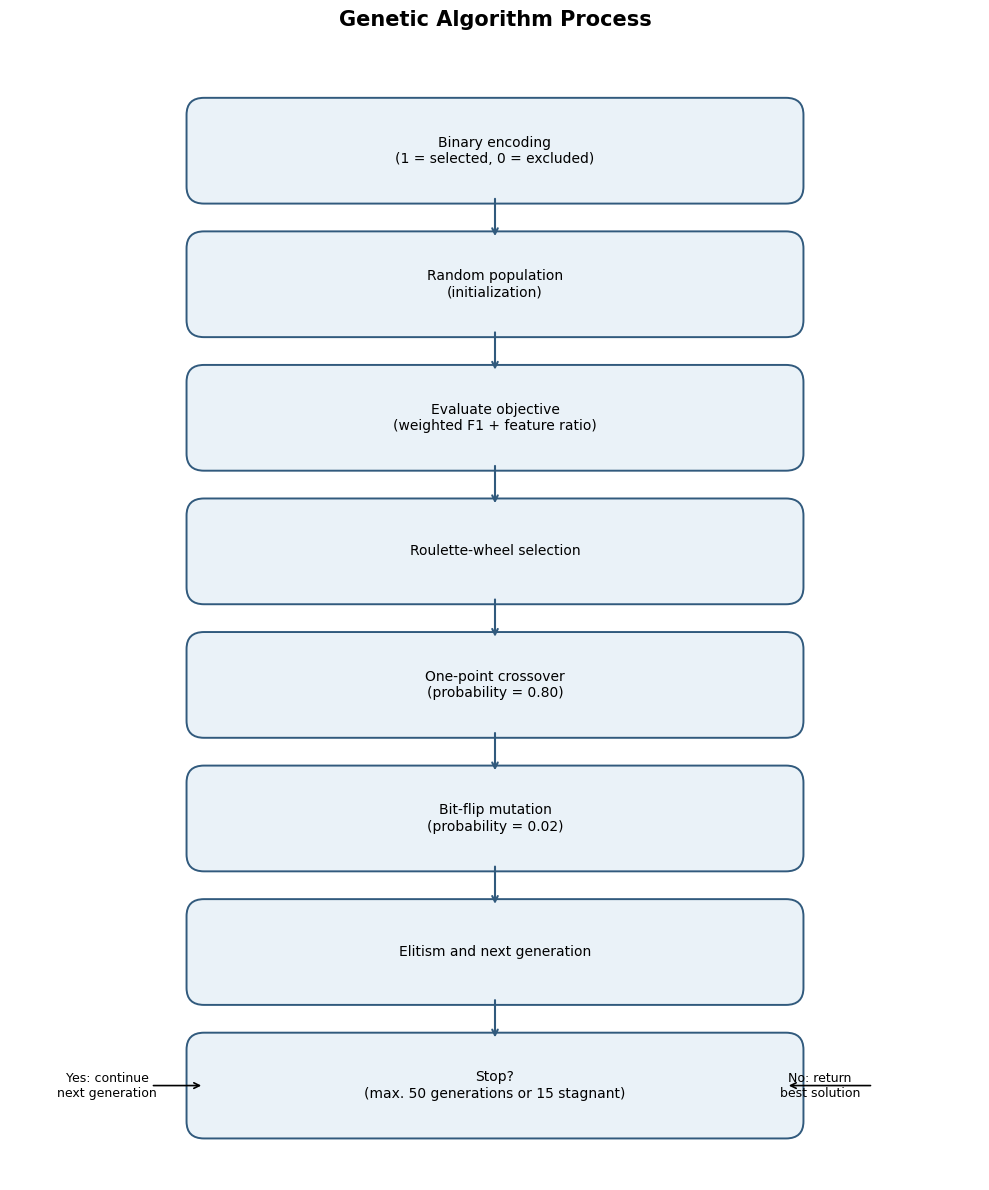

In [6]:
# Draw the Genetic Algorithm workflow used in this notebook.
from matplotlib.patches import FancyBboxPatch

workflow_steps = [
    "Binary encoding\n(1 = selected, 0 = excluded)",
    "Random population\n(initialization)",
    "Evaluate objective\n(weighted F1 + feature ratio)",
    "Roulette-wheel selection",
    "One-point crossover\n(probability = 0.80)",
    "Bit-flip mutation\n(probability = 0.02)",
    "Elitism and next generation",
    "Stop?\n(max. 50 generations or 15 stagnant)",
]

fig, ax = plt.subplots(figsize=(10, 12))
ax.set_xlim(0, 10)
ax.set_ylim(0, 12)
ax.axis("off")

ys = np.linspace(10.9, 1.0, len(workflow_steps))
for i, (step, y) in enumerate(zip(workflow_steps, ys)):
    box = FancyBboxPatch(
        (2.0, y - 0.38), 6.0, 0.76,
        boxstyle="round,pad=0.18",
        linewidth=1.4, edgecolor="#315a7d", facecolor="#eaf2f8"
    )
    ax.add_patch(box)
    ax.text(5.0, y, step, ha="center", va="center", fontsize=10)
    if i < len(workflow_steps) - 1:
        ax.annotate(
            "", xy=(5.0, ys[i + 1] + 0.48), xytext=(5.0, y - 0.48),
            arrowprops=dict(arrowstyle="->", lw=1.5, color="#315a7d")
        )

ax.text(8.35, 1.0, "No: return\nbest solution", ha="center", va="center", fontsize=9)
ax.annotate("", xy=(8.0, 1.0), xytext=(8.9, 1.0),
            arrowprops=dict(arrowstyle="->", lw=1.2))
ax.text(1.0, 1.0, "Yes: continue\nnext generation", ha="center", va="center", fontsize=9)
ax.annotate("", xy=(2.0, 1.0), xytext=(1.45, 1.0),
            arrowprops=dict(arrowstyle="->", lw=1.2))
ax.set_title("Genetic Algorithm Process", fontsize=15, weight="bold", pad=15)
plt.tight_layout()
plt.show()


## Final Evaluation and Baseline

### 6. Evaluating the selected features and the baseline
These functions train and test the Random Forest model. One evaluates the features selected by GA, while the other uses all features as a baseline. The test set is reserved for the final evaluation.

In [7]:
# Final evaluation on the test set only
def evaluate_selected_features(selector, data):
    selected = selector.best_position_.astype(bool)

    model = RandomForestClassifier(
        n_estimators=selector.model_estimators,
        random_state=selector.random_state,
        n_jobs=-1,
        class_weight="balanced",
    )
    model.fit(data["X_train"][:, selected], data["y_train"])
    predictions = model.predict(data["X_test"][:, selected])

    return {
        "accuracy": accuracy_score(data["y_test"], predictions),
        "precision_weighted": precision_score(
            data["y_test"], predictions, average="weighted", zero_division=0),
        "recall_weighted": recall_score(
            data["y_test"], predictions, average="weighted", zero_division=0),
        "f1_weighted": f1_score(
            data["y_test"], predictions, average="weighted", zero_division=0),
        "selected_count": int(selected.sum()),
        "total_features": len(selected),
        "selected_indices": np.flatnonzero(selected).tolist(),
    }


def evaluate_baseline_all_features(data, model_estimators=100, random_state=42):
    model = RandomForestClassifier(
        n_estimators=model_estimators,
        random_state=random_state,
        n_jobs=-1,
        class_weight="balanced",
    )
    model.fit(data["X_train"], data["y_train"])
    predictions = model.predict(data["X_test"])

    return {
        "accuracy": accuracy_score(data["y_test"], predictions),
        "precision_weighted": precision_score(
            data["y_test"], predictions, average="weighted", zero_division=0),
        "recall_weighted": recall_score(
            data["y_test"], predictions, average="weighted", zero_division=0),
        "f1_weighted": f1_score(
            data["y_test"], predictions, average="weighted", zero_division=0),
        "selected_count": data["X_train"].shape[1],
        "total_features": data["X_train"].shape[1],
    }




## Running One Dataset Experiment

### 7. Running one dataset and checking convergence
This function runs GA on one dataset and compares its test results with the all-features baseline. It also plots the convergence curve, which shows how the best objective value changes over generations.

In [8]:
# Run one experiment and plot convergence
def run_one_dataset(dataset_name="Sonar", all_raw=None):
    if all_raw is None:
        all_raw = load_raw_datasets()
    X, y = all_raw[dataset_name]
    data = prepare_dataset(X, y, random_state=RANDOM_STATE)

    print(dataset_name)
    print("Train:", data["X_train"].shape)
    print("Validation:", data["X_val"].shape)
    print("Test:", data["X_test"].shape)

    selector = GeneticAlgorithmFeatureSelector(
        pop_size=20,
        n_generations=50,
        crossover_rate=0.8,
        mutation_rate=0.02,
        elite=2,
        f1_weight=0.9,
        feature_weight=0.1,
        model_estimators=100,
        random_state=RANDOM_STATE,
        patience=15,
        verbose=True,
    )

    start = time.perf_counter()
    selector.fit(data["X_train"], data["X_val"], data["y_train"], data["y_val"])
    elapsed = time.perf_counter() - start

    final_results = evaluate_selected_features(selector, data)
    baseline_results = evaluate_baseline_all_features(
        data, model_estimators=100, random_state=RANDOM_STATE)

    print("\nFinal GA results on untouched test set:")
    print(final_results)
    print("\nBaseline using all features:")
    print(baseline_results)
    print(f"\nGA runtime: {elapsed:.2f} seconds")
    print("Selected feature indices:", selector.selected_features().tolist())

    plt.figure(figsize=(8, 4))
    plt.plot(selector.history_)
    plt.xlabel("Generation")
    plt.ylabel("Best Objective (lower is better)")
    plt.title(f"GA Convergence - {dataset_name}")
    plt.grid(alpha=0.3)
    plt.show()

    return selector, data, final_results, baseline_results



## Final GA and Baseline Comparison

### 8. Running the full comparison
This function repeats the experiment for each dataset and collects the results in one table. It records performance, feature reduction, runtime, and the number of generations. It also saves a convergence plot for each dataset.

In [9]:
#Repeated experiment: GA versus Baseline across multiple random seeds
def run_repeated_ga_baseline_comparison(
    dataset_names=None,
    seeds=(42, 43, 44, 45, 46),
    pop_size=20,
    n_generations=50,
    patience=15,
    model_estimators=100,
    save_csv=True,
    all_raw=None,
):
    """
    Run a separate stratified train/validation/test split for each seed.
    For every seed, evaluate the all-feature Baseline and GA on the same
    untouched test split. Return per-run results and mean/std summary.
    """
    if all_raw is None:
        all_raw = load_raw_datasets()
    if dataset_names is None:
        dataset_names = list(all_raw.keys())

    run_rows = []
    convergence_curves = {}

    for dataset_name in dataset_names:
        print("\n" + "=" * 76)
        print(f"Dataset: {dataset_name}")

        X, y = all_raw[dataset_name]
        convergence_curves[dataset_name] = []

        for run_number, seed in enumerate(seeds, start=1):
            print(f"\nRun {run_number}/{len(seeds)} | seed={seed}")
            data = prepare_dataset(X, y, random_state=seed)

            # Baseline uses all features and the exact same split as GA.
            baseline_start = time.perf_counter()
            with measure_process_memory():
                baseline = evaluate_baseline_all_features(
                    data, model_estimators=model_estimators, random_state=seed
                )
            baseline_time = time.perf_counter() - baseline_start
            baseline_memory = measure_process_memory.result.copy()

            selector = GeneticAlgorithmFeatureSelector(
                pop_size=pop_size,
                n_generations=n_generations,
                crossover_rate=0.8,
                mutation_rate=0.02,
                elite=2,
                f1_weight=0.9,
                feature_weight=0.1,
                model_estimators=model_estimators,
                random_state=seed,
                patience=patience,
                verbose=False,
            )

            ga_start = time.perf_counter()
            with measure_process_memory():
                selector.fit(
                    data["X_train"], data["X_val"],
                    data["y_train"], data["y_val"]
                )
                ga = evaluate_selected_features(selector, data)
            ga_search_time = time.perf_counter() - ga_start
            ga_memory = measure_process_memory.result.copy()

            feature_reduction = 100 * (
                1 - ga["selected_count"] / baseline["total_features"]
            )
            f1_difference = ga["f1_weighted"] - baseline["f1_weighted"]

            run_rows.append({
                "dataset": dataset_name,
                "run": run_number,
                "seed": seed,
                "total_features": baseline["total_features"],
                "ga_selected_features": ga["selected_count"],
                "feature_reduction_percent": feature_reduction,
                "baseline_accuracy": baseline["accuracy"],
                "ga_accuracy": ga["accuracy"],
                "baseline_precision_weighted": baseline["precision_weighted"],
                "ga_precision_weighted": ga["precision_weighted"],
                "baseline_recall_weighted": baseline["recall_weighted"],
                "ga_recall_weighted": ga["recall_weighted"],
                "baseline_f1_weighted": baseline["f1_weighted"],
                "ga_f1_weighted": ga["f1_weighted"],
                "f1_difference_ga_minus_baseline": f1_difference,
                "baseline_time_seconds": baseline_time,
                "ga_search_time_seconds": ga_search_time,
                "baseline_peak_rss_mb": baseline_memory["peak_rss_mb"],
                "baseline_peak_memory_increase_mb": baseline_memory["peak_increment_mb"],
                "ga_peak_rss_mb": ga_memory["peak_rss_mb"],
                "ga_peak_memory_increase_mb": ga_memory["peak_increment_mb"],
                "ga_best_objective": selector.best_objective_,
                "ga_iterations_run": len(selector.history_),
                "ga_evaluations": len(selector.cache_),
                "ga_selected_indices_zero_based": str(ga["selected_indices"]),
            })
            convergence_curves[dataset_name].append(selector.history_)

            print(
                f"Baseline F1={baseline['f1_weighted']:.4f} | "
                f"GA F1={ga['f1_weighted']:.4f} | "
                f"Features={ga['selected_count']}/{baseline['total_features']} | "
                f"GA time={ga_search_time:.1f}s | "
                f"RAM peak increase Baseline={baseline_memory['peak_increment_mb']:.1f} MB, "
                f"GA={ga_memory['peak_increment_mb']:.1f} MB"
            )

        # Mean convergence curve across runs (runs may stop at different generations).
        max_len = max(len(curve) for curve in convergence_curves[dataset_name])
        padded = np.full((len(seeds), max_len), np.nan)
        for i, curve in enumerate(convergence_curves[dataset_name]):
            padded[i, :len(curve)] = curve
        mean_curve = np.nanmean(padded, axis=0)

        os.makedirs("convergence_plots", exist_ok=True)
        plt.figure(figsize=(8, 4))
        plt.plot(range(1, len(mean_curve) + 1), mean_curve, linewidth=2)
        plt.xlabel("Generation")
        plt.ylabel("Mean Best Objective (lower is better)")
        plt.title(f"Mean GA Convergence - {dataset_name} ({len(seeds)} runs)")
        plt.grid(alpha=0.3)
        plt.savefig(
            f"convergence_plots/{dataset_name}_GA_mean_convergence.png",
            dpi=200, bbox_inches="tight",
        )
        plt.show()

    per_run = pd.DataFrame(run_rows)

    metric_columns = [
        "ga_selected_features", "feature_reduction_percent",
        "baseline_accuracy", "ga_accuracy",
        "baseline_precision_weighted", "ga_precision_weighted",
        "baseline_recall_weighted", "ga_recall_weighted",
        "baseline_f1_weighted", "ga_f1_weighted",
        "f1_difference_ga_minus_baseline",
        "baseline_time_seconds", "ga_search_time_seconds",
        "baseline_peak_rss_mb", "baseline_peak_memory_increase_mb",
        "ga_peak_rss_mb", "ga_peak_memory_increase_mb",
        "ga_best_objective", "ga_iterations_run", "ga_evaluations",
    ]

    summary_rows = []
    for dataset_name, group in per_run.groupby("dataset", sort=False):
        row = {
            "dataset": dataset_name,
            "runs": len(group),
            "total_features": int(group["total_features"].iloc[0]),
        }
        for col in metric_columns:
            row[f"{col}_mean"] = group[col].mean()
            row[f"{col}_std"] = group[col].std(ddof=1) if len(group) > 1 else 0.0
        summary_rows.append(row)

    summary = pd.DataFrame(summary_rows)

    if save_csv:
        per_run.to_csv("ga_vs_baseline_all_runs.csv", index=False)
        summary.to_csv("ga_vs_baseline_summary.csv", index=False)
        # Backward-compatible filename: now contains the multi-run summary.
        summary.to_csv("ga_vs_baseline_comparison.csv", index=False)
        print("\nSaved:")
        print("- ga_vs_baseline_all_runs.csv (one row per dataset and seed)")
        print("- ga_vs_baseline_summary.csv (mean and standard deviation)")
        print("- ga_vs_baseline_comparison.csv (same summary; compatibility)")
        print("RAM columns report peak process RSS and peak increase (MB) for Baseline and GA.")
    return per_run, summary


## Running the Experiments and Displaying Results

### 8. Repeated experiments and final comparison

The final comparison repeats the complete experiment five times per dataset using seeds **42, 43, 44, 45, and 46**. Each seed creates its own stratified train/validation/test split. Baseline and GA are evaluated on the same test split within each run, ensuring a fair paired comparison.

The notebook saves:
- `ga_vs_baseline_all_runs.csv`: individual results for every dataset and seed.
- `ga_vs_baseline_summary.csv`: mean and sample standard deviation across runs.
- `ga_vs_baseline_comparison.csv`: compatibility copy of the summary table.

The summary reports mean ± standard deviation for weighted F1, accuracy, selected feature count, feature reduction, runtime, objective value, generations, and evaluations. Mean GA convergence plots are also saved. Run all cells from top to bottom to generate the new empirical results; the earlier single-run results are not substituted for these repeated-run results.


**Memory measurement:** The notebook measures process RAM (RSS) separately for Baseline and GA using `psutil`. It records peak RSS and the peak increase above the process memory at the start of each measured block. RSS includes native allocations used by NumPy/scikit-learn; sampling every 10 ms means very short-lived peaks may be missed. Memory figures are measured during each run and summarized as mean ± standard deviation.



Dataset: Parkinsons

Run 1/5 | seed=42
Baseline F1=0.9217 | GA F1=0.9242 | Features=4/22 | GA time=91.9s | RAM peak increase Baseline=1.1 MB, GA=1.4 MB

Run 2/5 | seed=43
Baseline F1=0.9217 | GA F1=0.8402 | Features=4/22 | GA time=89.7s | RAM peak increase Baseline=0.1 MB, GA=0.1 MB

Run 3/5 | seed=44
Baseline F1=0.8934 | GA F1=0.9217 | Features=5/22 | GA time=99.4s | RAM peak increase Baseline=0.1 MB, GA=0.1 MB

Run 4/5 | seed=45
Baseline F1=0.8319 | GA F1=0.8934 | Features=6/22 | GA time=105.9s | RAM peak increase Baseline=0.0 MB, GA=0.2 MB

Run 5/5 | seed=46
Baseline F1=0.8974 | GA F1=0.8974 | Features=3/22 | GA time=94.4s | RAM peak increase Baseline=0.1 MB, GA=0.1 MB


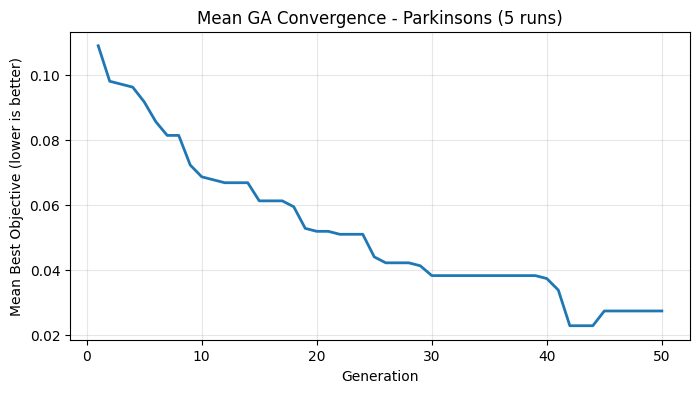


Dataset: Sonar

Run 1/5 | seed=42
Baseline F1=0.8531 | GA F1=0.7777 | Features=24/60 | GA time=221.8s | RAM peak increase Baseline=0.1 MB, GA=0.5 MB

Run 2/5 | seed=43
Baseline F1=0.8799 | GA F1=0.8069 | Features=19/60 | GA time=166.8s | RAM peak increase Baseline=0.1 MB, GA=0.6 MB

Run 3/5 | seed=44
Baseline F1=0.7505 | GA F1=0.8299 | Features=24/60 | GA time=76.3s | RAM peak increase Baseline=0.1 MB, GA=0.1 MB

Run 4/5 | seed=45
Baseline F1=0.7376 | GA F1=0.8571 | Features=19/60 | GA time=206.8s | RAM peak increase Baseline=0.1 MB, GA=0.2 MB

Run 5/5 | seed=46
Baseline F1=0.7552 | GA F1=0.7283 | Features=27/60 | GA time=224.9s | RAM peak increase Baseline=0.0 MB, GA=0.1 MB


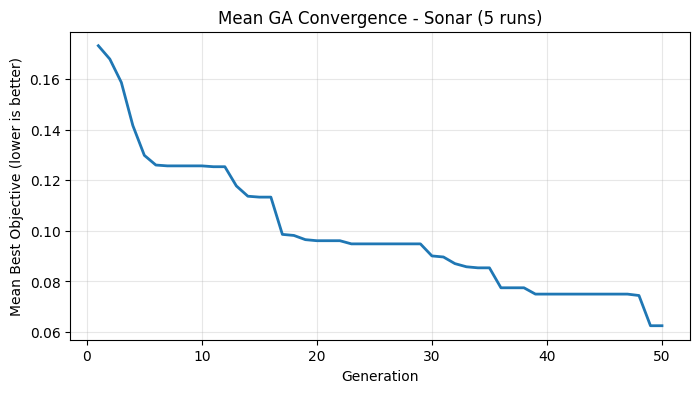


Dataset: Arrhythmia

Run 1/5 | seed=42
Baseline F1=0.5696 | GA F1=0.6114 | Features=129/279 | GA time=345.4s | RAM peak increase Baseline=2.4 MB, GA=5.5 MB

Run 2/5 | seed=43
Baseline F1=0.5588 | GA F1=0.5718 | Features=123/279 | GA time=228.5s | RAM peak increase Baseline=0.0 MB, GA=0.2 MB

Run 3/5 | seed=44
Baseline F1=0.6333 | GA F1=0.6263 | Features=134/279 | GA time=199.1s | RAM peak increase Baseline=0.0 MB, GA=0.1 MB

Run 4/5 | seed=45
Baseline F1=0.5904 | GA F1=0.5925 | Features=130/279 | GA time=350.3s | RAM peak increase Baseline=0.1 MB, GA=0.1 MB

Run 5/5 | seed=46
Baseline F1=0.6276 | GA F1=0.6462 | Features=146/279 | GA time=169.7s | RAM peak increase Baseline=0.1 MB, GA=0.2 MB


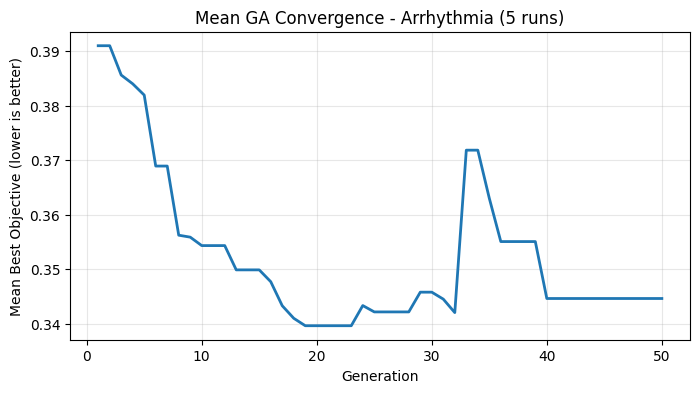


Saved:
- ga_vs_baseline_all_runs.csv (one row per dataset and seed)
- ga_vs_baseline_summary.csv (mean and standard deviation)
- ga_vs_baseline_comparison.csv (same summary; compatibility)
RAM columns report peak process RSS and peak increase (MB) for Baseline and GA.


### GA versus Baseline: Mean ± Standard Deviation Across 5 Runs

dataset,runs,total_features,ga_selected_features_mean,ga_selected_features_std,feature_reduction_percent_mean,feature_reduction_percent_std,baseline_accuracy_mean,baseline_accuracy_std,ga_accuracy_mean,ga_accuracy_std,baseline_precision_weighted_mean,baseline_precision_weighted_std,ga_precision_weighted_mean,ga_precision_weighted_std,baseline_recall_weighted_mean,baseline_recall_weighted_std,ga_recall_weighted_mean,ga_recall_weighted_std,baseline_f1_weighted_mean,baseline_f1_weighted_std,ga_f1_weighted_mean,ga_f1_weighted_std,f1_difference_ga_minus_baseline_mean,f1_difference_ga_minus_baseline_std,baseline_time_seconds_mean,baseline_time_seconds_std,ga_search_time_seconds_mean,ga_search_time_seconds_std,baseline_peak_rss_mb_mean,baseline_peak_rss_mb_std,baseline_peak_memory_increase_mb_mean,baseline_peak_memory_increase_mb_std,ga_peak_rss_mb_mean,ga_peak_rss_mb_std,ga_peak_memory_increase_mb_mean,ga_peak_memory_increase_mb_std,ga_best_objective_mean,ga_best_objective_std,ga_iterations_run_mean,ga_iterations_run_std,ga_evaluations_mean,ga_evaluations_std
Parkinsons,5,22,4.400000,1.140200,80.000000,5.182600,0.897400,0.031400,0.897400,0.031400,0.896400,0.031600,0.896400,0.034500,0.897400,0.031400,0.897400,0.031400,0.893200,0.036800,0.895400,0.033800,0.002200,0.053000,0.282200,0.042600,96.269300,6.482900,269.614100,0.632700,0.266400,0.480000,269.937500,0.099500,0.368000,0.550700,0.037300,0.014000,43.200000,4.086600,364.200000,24.499000
Sonar,5,60,22.600000,3.507100,62.333300,5.845200,0.800000,0.064300,0.804800,0.045800,0.819900,0.066400,0.822300,0.037000,0.800000,0.064300,0.804800,0.045800,0.795300,0.066000,0.800000,0.049600,0.004700,0.089800,0.276300,0.013800,179.315700,62.080600,274.997700,0.475700,0.052300,0.003500,275.231200,0.270600,0.285900,0.252900,0.096100,0.050200,40.400000,14.519000,630.600000,219.559300
Arrhythmia,5,279,132.400000,8.561500,52.544800,3.068700,0.670300,0.032000,0.676900,0.031700,0.605600,0.035500,0.632200,0.030900,0.670300,0.032000,0.676900,0.031700,0.595900,0.033500,0.609600,0.028900,0.013700,0.018600,0.567400,0.144700,258.603600,84.115400,287.200000,2.513200,0.525000,1.060400,288.372700,0.127100,1.222700,2.408800,0.325200,0.027700,36.600000,12.641200,678.400000,227.902000


In [10]:
per_run_results, comparison = run_repeated_ga_baseline_comparison(
    dataset_names=["Parkinsons", "Sonar", "Arrhythmia"],
    seeds=[42, 43, 44, 45, 46],
    pop_size=20,
    n_generations=50,
    patience=15,
    model_estimators=100,
    save_csv=True,
)

style_table(comparison.round(4), "GA versus Baseline: Mean ± Standard Deviation Across 5 Runs")


### 10. Extra plots for the results
These plots use the comparison table created above. They make it easier to compare test performance, the number of selected features, feature reduction, and runtime across the datasets.\nThe workflow diagram summarizes the algorithm stages, and the selected-feature plot tracks model complexity across generations.

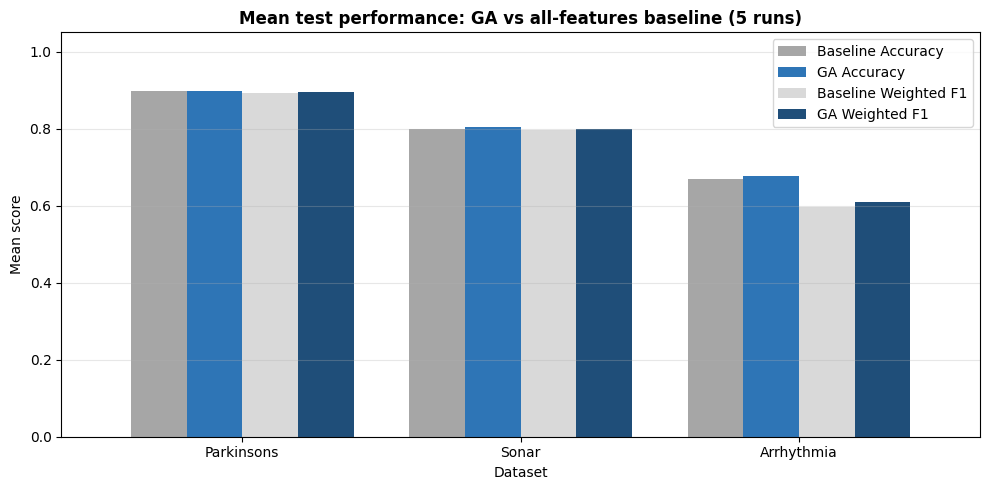

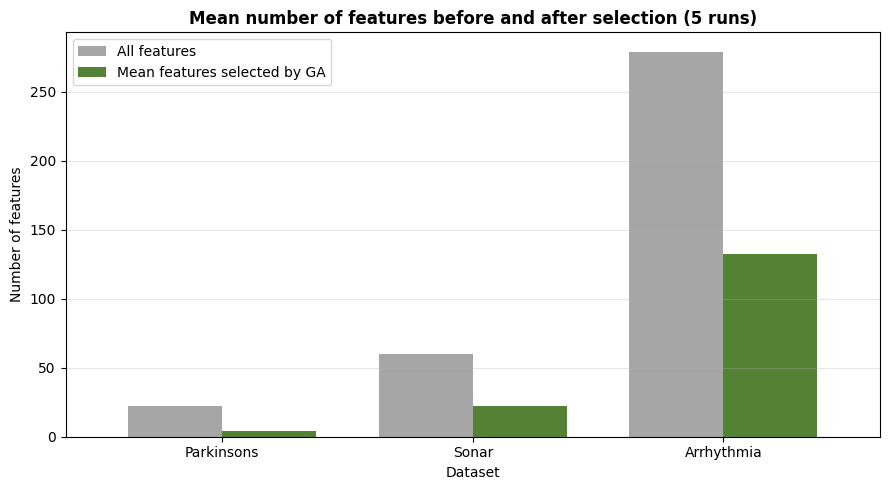

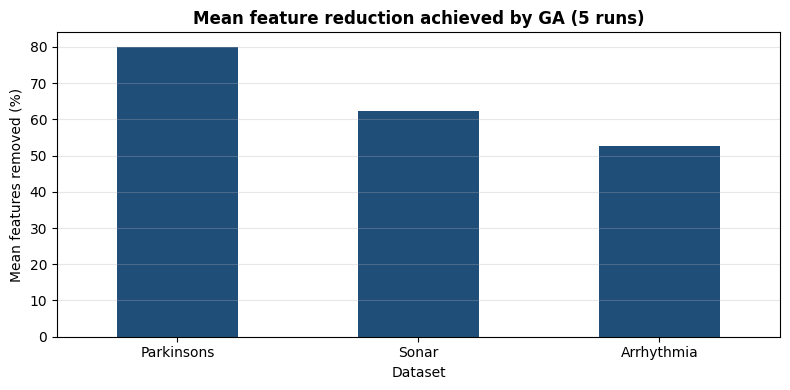

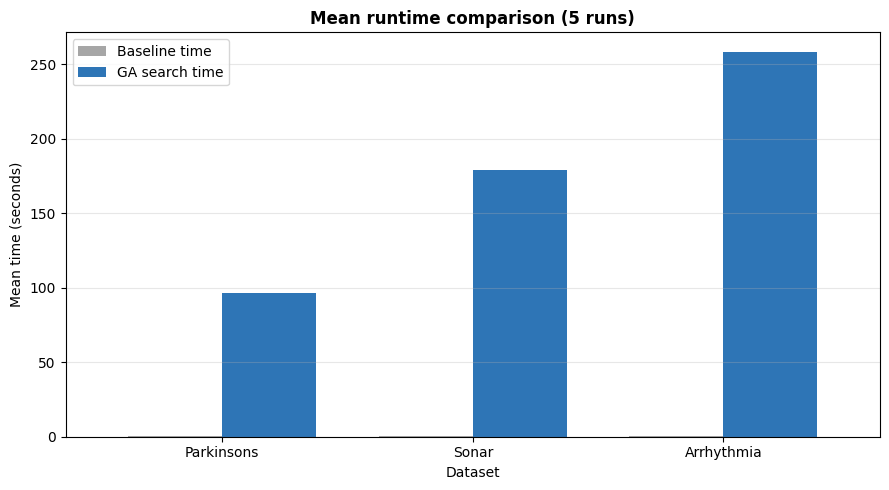

### Weighted F1: Mean ± Standard Deviation

dataset,baseline_f1_weighted_mean,baseline_f1_weighted_std,ga_f1_weighted_mean,ga_f1_weighted_std
Parkinsons,0.893200,0.036800,0.895400,0.033800
Sonar,0.795300,0.066000,0.800000,0.049600
Arrhythmia,0.595900,0.033500,0.609600,0.028900


In [11]:
import matplotlib.pyplot as plt

colors_scores = ['#A6A6A6', '#2E75B6', '#D9D9D9', '#1F4E79']
colors_features = ['#A6A6A6', '#548235']
color_reduction = '#1F4E79'
colors_time = ['#A6A6A6', '#2E75B6']
# 1. Compare mean test scores across the five repeated runs
score_columns = [
    "baseline_accuracy_mean", "ga_accuracy_mean",
    "baseline_f1_weighted_mean", "ga_f1_weighted_mean"
]
score_plot = comparison.set_index("dataset")[score_columns]
ax = score_plot.plot(kind="bar", figsize=(10, 5), width=0.8, color=colors_scores)
ax.set_title("Mean test performance: GA vs all-features baseline (5 runs)", fontsize=12, fontweight='bold')
ax.set_xlabel("Dataset")
ax.set_ylabel("Mean score")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.legend(["Baseline Accuracy", "GA Accuracy",
            "Baseline Weighted F1", "GA Weighted F1"])
plt.tight_layout()
plt.show()

# 2. Mean number of selected features
feature_plot = comparison.set_index("dataset")[
    ["total_features", "ga_selected_features_mean"]
]
ax = feature_plot.plot(kind="bar", figsize=(9, 5), width=0.75, color=colors_features)
ax.set_title("Mean number of features before and after selection (5 runs)", fontsize=12, fontweight='bold')
ax.set_xlabel("Dataset")
ax.set_ylabel("Number of features")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.legend(["All features", "Mean features selected by GA"])
plt.tight_layout()
plt.show()

# 3. Mean percentage of features removed
ax = comparison.plot(x="dataset", y="feature_reduction_percent_mean",
                     kind="bar", figsize=(8, 4), legend=False, color=color_reduction)
ax.set_title("Mean feature reduction achieved by GA (5 runs)", fontsize=12, fontweight='bold')
ax.set_xlabel("Dataset")
ax.set_ylabel("Mean features removed (%)")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 4. Mean runtime comparison
time_plot = comparison.set_index("dataset")[
    ["baseline_time_seconds_mean", "ga_search_time_seconds_mean"]
]
ax = time_plot.plot(kind="bar", figsize=(9, 5), width=0.75, color=colors_time)
ax.set_title("Mean runtime comparison (5 runs)", fontsize=12, fontweight='bold')
ax.set_xlabel("Dataset")
ax.set_ylabel("Mean time (seconds)")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.legend(["Baseline time", "GA search time"])
plt.tight_layout()
plt.show()

# Report F1 variability as mean ± standard deviation.
f1_summary = comparison[[
    "dataset", "baseline_f1_weighted_mean", "baseline_f1_weighted_std",
    "ga_f1_weighted_mean", "ga_f1_weighted_std"
]].copy()
style_table(f1_summary.round(4), "Weighted F1: Mean ± Standard Deviation")

# Part 2: Binary PSO (BPSO)

In [12]:
!pip install -q psutil xlsxwriter

from pathlib import Path
# ============================================================
# Binary PSO for Feature Selection
# مشروع اختيار الخصائص باستخدام تحسين سرب الجسيمات الثنائي
# ============================================================

import time
import os
import threading
import psutil
from contextlib import contextmanager
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

RANDOM_STATE = 42


@contextmanager
def measure_process_memory(interval=0.01):
    """Measure process RSS and peak increase during a code block (MB)."""
    process = psutil.Process(os.getpid())
    start_rss = process.memory_info().rss
    peak_rss = [start_rss]
    stop_event = threading.Event()

    def sample_memory():
        while not stop_event.is_set():
            try:
                peak_rss[0] = max(peak_rss[0], process.memory_info().rss)
            except psutil.Error:
                pass
            stop_event.wait(interval)

    monitor = threading.Thread(target=sample_memory, daemon=True)
    monitor.start()
    try:
        yield
    finally:
        try:
            peak_rss[0] = max(peak_rss[0], process.memory_info().rss)
        finally:
            stop_event.set()
            monitor.join()
        mb = 1024 ** 2
        measure_process_memory.result = {
            "start_rss_mb": start_rss / mb,
            "peak_rss_mb": peak_rss[0] / mb,
            "peak_memory_increase_mb": max(0, peak_rss[0] - start_rss) / mb,
        }

In [13]:
# ------------------------------------------------------------
# 1) تحميل البيانات الخام

# ------------------------------------------------------------
def load_raw_datasets():
    parkinsons_url = (
        "https://archive.ics.uci.edu/ml/"
        "machine-learning-databases/parkinsons/parkinsons.data"
    )

    parkinsons = pd.read_csv(parkinsons_url)
    X_p = parkinsons.drop(columns=["name", "status"])
    y_p = parkinsons["status"].to_numpy()

    sonar = fetch_openml(name="sonar", version=1, as_frame=True)
    X_s = sonar.data.copy()
    y_s = sonar.target.to_numpy()

    arrhythmia = fetch_openml(name="arrhythmia", version=1, as_frame=True)
    X_a = arrhythmia.data.copy()
    y_a = arrhythmia.target.to_numpy()

    return {
        "Parkinsons": (X_p, y_p),
        "Sonar": (X_s, y_s),
        "Arrhythmia": (X_a, y_a),
    }


# ------------------------------------------------------------
# 2) تجهيز صحيح: التقسيم أولًا ثم imputation/scaling على التدريب فقط
# ------------------------------------------------------------
def prepare_dataset(X, y, test_size=0.20, val_size=0.20, random_state=42):
    X = X.apply(pd.to_numeric, errors="coerce")

    # تحويل التسميات إلى أرقام، ويعمل للثنائي ومتعدد الفئات
    label_encoder = LabelEncoder()
    y = label_encoder.fit_transform(np.asarray(y).astype(str))

    X_train_val, X_test, y_train_val, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        stratify=y,
        random_state=random_state,
    )


    X_train, X_val, y_train, y_val = train_test_split(
        X_train_val,
        y_train_val,
        test_size=val_size,
        stratify=y_train_val,
        random_state=random_state,
    )

    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()


    X_train = imputer.fit_transform(X_train)
    X_val = imputer.transform(X_val)
    X_test = imputer.transform(X_test)

    X_train = scaler.fit_transform(X_train)
    X_val = scaler.transform(X_val)
    X_test = scaler.transform(X_test)

    return {
        "X_train": X_train,
        "X_val": X_val,
        "X_test": X_test,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test,
        "label_encoder": label_encoder,
    }

In [14]:
# ------------------------------------------------------------
# 3) Binary Particle Swarm Optimization
# ------------------------------------------------------------
class BinaryPSOFeatureSelector:
    """اختيار الخصائص بتمثيل ثنائي: 1 اختيار، 0 عدم اختيار."""

    def __init__(
        self,
        n_particles=20,
        n_iterations=50,
        w=0.7,
        c1=1.5,
        c2=1.5,
        f1_weight=0.9,
        feature_weight=0.1,
        model_estimators=100,
        random_state=42,
        patience=None,
        verbose=True,
    ):
        self.n_particles = n_particles
        self.n_iterations = n_iterations
        self.w = w
        self.c1 = c1
        self.c2 = c2
        self.f1_weight = f1_weight
        self.feature_weight = feature_weight
        self.model_estimators = model_estimators
        self.random_state = random_state
        self.patience = patience
        self.verbose = verbose

        self.best_position_ = None
        self.best_objective_ = None
        self.history_ = []
        self.history_n_features_ = []
        self.cache_ = {}

    @staticmethod
    def sigmoid(values):
        # القصّ يمنع overflow عند exp
        values = np.clip(values, -10, 10)
        return 1.0 / (1.0 + np.exp(-values))

    def _objective(self, position, X_train, X_val, y_train, y_val):
        key = tuple(position.astype(int).tolist())
        if key in self.cache_:
            return self.cache_[key]

        selected = position.astype(bool)
        n_selected = int(selected.sum())

        # حل بلا أي خاصية غير صالح
        if n_selected == 0:
            return 1.0

        model = RandomForestClassifier(
            n_estimators=self.model_estimators,
            random_state=self.random_state,
            n_jobs=-1,
            class_weight="balanced",
        )
        model.fit(X_train[:, selected], y_train)
        predictions = model.predict(X_val[:, selected])

        f1 = f1_score(
            y_val,
            predictions,
            average="weighted",
            zero_division=0,
        )
        feature_ratio = n_selected / len(position)

        # نُصغّر هذه القيمة: أداء عالٍ + عدد خصائص قليل
        objective = (
            self.f1_weight * (1.0 - f1)
            + self.feature_weight * feature_ratio
        )

        self.cache_[key] = float(objective)
        return float(objective)

    def fit(self, X_train, X_val, y_train, y_val):
        rng = np.random.default_rng(self.random_state)
        n_features = X_train.shape[1]

        # position: مصفوفة 0/1، velocity: قيم حقيقية
        positions = rng.integers(
            0, 2, size=(self.n_particles, n_features)
        ).astype(int)
        velocities = rng.uniform(
            -1, 1, size=(self.n_particles, n_features)
        )

        # ضمان اختيار خاصية واحدة على الأقل لكل جسيم
        for i in range(self.n_particles):
            if positions[i].sum() == 0:
                positions[i, rng.integers(0, n_features)] = 1

        scores = np.array([
            self._objective(p, X_train, X_val, y_train, y_val)
            for p in positions
        ])

        personal_best_positions = positions.copy()
        personal_best_scores = scores.copy()

        best_index = int(np.argmin(personal_best_scores))
        global_best_position = personal_best_positions[best_index].copy()
        global_best_score = float(personal_best_scores[best_index])

        no_improvement = 0

        for iteration in range(self.n_iterations):
            previous_best = global_best_score

            for i in range(self.n_particles):
                r1 = rng.random(n_features)
                r2 = rng.random(n_features)

                velocities[i] = (
                    self.w * velocities[i]
                    + self.c1 * r1 * (
                        personal_best_positions[i] - positions[i]
                    )
                    + self.c2 * r2 * (
                        global_best_position - positions[i]
                    )
                )

                probabilities = self.sigmoid(velocities[i])
                positions[i] = (
                    rng.random(n_features) < probabilities
                ).astype(int)

                if positions[i].sum() == 0:
                    positions[i, rng.integers(0, n_features)] = 1

                current_score = self._objective(
                    positions[i], X_train, X_val, y_train, y_val
                )

                if current_score < personal_best_scores[i]:
                    personal_best_scores[i] = current_score
                    personal_best_positions[i] = positions[i].copy()

            best_index = int(np.argmin(personal_best_scores))
            if personal_best_scores[best_index] < global_best_score:
                global_best_score = float(personal_best_scores[best_index])
                global_best_position = personal_best_positions[
                    best_index
                ].copy()

            self.history_.append(global_best_score)
            self.history_n_features_.append(
                int(global_best_position.sum())
            )

            if global_best_score < previous_best:
                no_improvement = 0
            else:
                no_improvement += 1

            if self.verbose:
                print(
                    f"Iteration {iteration + 1:03d}/{self.n_iterations} | "
                    f"Best Objective: {global_best_score:.5f} | "
                    f"Selected Features: {global_best_position.sum()}"
                )

            if (
                self.patience is not None
                and no_improvement >= self.patience
            ):
                if self.verbose:
                    print("Early stopping: no improvement.")
                break

        self.best_position_ = global_best_position
        self.best_objective_ = global_best_score
        return self

    def selected_features(self):
        if self.best_position_ is None:
            raise RuntimeError("Run fit() before selected_features().")
        return np.flatnonzero(self.best_position_ == 1)

In [15]:
# ------------------------------------------------------------
# 4) التقييم النهائي على Test فقط بعد انتهاء BPSO
# ------------------------------------------------------------
def evaluate_selected_features(selector, data):
    selected = selector.best_position_.astype(bool)

    model = RandomForestClassifier(
        n_estimators=selector.model_estimators,
        random_state=selector.random_state,
        n_jobs=-1,
        class_weight="balanced",
    )
    model.fit(data["X_train"][:, selected], data["y_train"])
    predictions = model.predict(data["X_test"][:, selected])

    return {
        "accuracy": accuracy_score(data["y_test"], predictions),
        "precision_weighted": precision_score(
            data["y_test"], predictions,
            average="weighted", zero_division=0
        ),
        "recall_weighted": recall_score(
            data["y_test"], predictions,
            average="weighted", zero_division=0
        ),
        "f1_weighted": f1_score(
            data["y_test"], predictions,
            average="weighted", zero_division=0
        ),
        "selected_count": int(selected.sum()),
        "total_features": len(selected),
        "selected_indices": np.flatnonzero(selected).tolist(),
    }


def evaluate_baseline_all_features(data, model_estimators=100, random_state=42):
    model = RandomForestClassifier(
        n_estimators=model_estimators,
        random_state=random_state,
        n_jobs=-1,
        class_weight="balanced",
    )
    model.fit(data["X_train"], data["y_train"])
    predictions = model.predict(data["X_test"])

    return {
        "accuracy": accuracy_score(data["y_test"], predictions),
        "precision_weighted": precision_score(
            data["y_test"], predictions,
            average="weighted", zero_division=0
        ),
        "recall_weighted": recall_score(
            data["y_test"], predictions,
            average="weighted", zero_division=0
        ),
        "f1_weighted": f1_score(
            data["y_test"], predictions,
            average="weighted", zero_division=0
        ),
        "selected_count": data["X_train"].shape[1],
        "total_features": data["X_train"].shape[1],
    }

In [16]:
# ------------------------------------------------------------
# 5) تشغيل تجربة واحدة ورسم التقارب
# ------------------------------------------------------------
def run_one_dataset(dataset_name="Sonar"):
    all_raw = load_raw_datasets()
    X, y = all_raw[dataset_name]
    data = prepare_dataset(X, y, random_state=RANDOM_STATE)

    print(dataset_name)
    print("Train:", data["X_train"].shape)
    print("Validation:", data["X_val"].shape)
    print("Test:", data["X_test"].shape)

    selector = BinaryPSOFeatureSelector(
        n_particles=20,
        n_iterations=50,
        w=0.7,
        c1=1.5,
        c2=1.5,
        f1_weight=0.9,
        feature_weight=0.1,
        model_estimators=100,
        random_state=RANDOM_STATE,
        patience=15,
        verbose=True,
    )

    start = time.perf_counter()
    selector.fit(
        data["X_train"],
        data["X_val"],
        data["y_train"],
        data["y_val"],
    )
    elapsed = time.perf_counter() - start

    selected = selector.selected_features()
    final_results = evaluate_selected_features(selector, data)
    baseline_results = evaluate_baseline_all_features(
        data,
        model_estimators=100,
        random_state=RANDOM_STATE,
    )

    print("\nFinal BPSO results on untouched test set:")
    print(final_results)
    print("\nBaseline using all features:")
    print(baseline_results)
    print(f"\nBPSO runtime: {elapsed:.2f} seconds")
    print("Selected feature indices:", selected.tolist())

    plt.figure(figsize=(8, 4))
    plt.plot(selector.history_)
    plt.xlabel("Iteration")
    plt.ylabel("Best Objective (lower is better)")
    plt.title(f"BPSO Convergence - {dataset_name}")
    plt.grid(alpha=0.3)
    plt.show()

    return selector, data, final_results, baseline_results


# ------------------------------------------------------------
# 6) تشغيل المجموعات الثلاث (للتجربة النهائية)
# ------------------------------------------------------------
def run_all_datasets_once():
    all_raw = load_raw_datasets()
    rows = []

    for dataset_name, (X, y) in all_raw.items():
        print("\n" + "=" * 60)
        print(f"Running BPSO on {dataset_name}")
        data = prepare_dataset(X, y, random_state=RANDOM_STATE)

        selector = BinaryPSOFeatureSelector(
            n_particles=20,
            n_iterations=50,
            w=0.7,
            c1=1.5,
            c2=1.5,
            model_estimators=100,
            random_state=RANDOM_STATE,
            patience=15,
            verbose=False,
        )
        start = time.perf_counter()
        selector.fit(
            data["X_train"], data["X_val"],
            data["y_train"], data["y_val"]
        )
        runtime = time.perf_counter() - start

        result = evaluate_selected_features(selector, data)
        result.update({
            "dataset": dataset_name,
            "runtime_seconds": runtime,
            "best_objective": selector.best_objective_,
            "iterations_run": len(selector.history_),
        })
        rows.append(result)

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# 7) المقارنة النهائية: BPSO مقابل Baseline تلقائيًا
# ------------------------------------------------------------
def run_final_bpso_baseline_comparison(
    dataset_names=None,
    n_particles=20,
    n_iterations=50,
    patience=15,
    model_estimators=100,
    random_state=42,
    save_csv=True,
):
    """تشغيل BPSO وBaseline على كل Dataset وإرجاع جدول مقارنة."""
    all_raw = load_raw_datasets()

    if dataset_names is None:
        dataset_names = list(all_raw.keys())

    rows = []

    for dataset_name in dataset_names:
        print("\n" + "=" * 70)
        print(f"Dataset: {dataset_name}")

        X, y = all_raw[dataset_name]
        data = prepare_dataset(X, y, random_state=random_state)

        # Baseline: Random Forest باستخدام جميع الخصائص
        baseline_start = time.perf_counter()
        with measure_process_memory():
            baseline = evaluate_baseline_all_features(
                data,
                model_estimators=model_estimators,
                random_state=random_state,
            )
        baseline_time = time.perf_counter() - baseline_start
        baseline_memory = measure_process_memory.result.copy()

        # BPSO: البحث عن أفضل مجموعة خصائص باستخدام Validation فقط
        selector = BinaryPSOFeatureSelector(
            n_particles=n_particles,
            n_iterations=n_iterations,
            w=0.7,
            c1=1.5,
            c2=1.5,
            f1_weight=0.9,
            feature_weight=0.1,
            model_estimators=model_estimators,
            random_state=random_state,
            patience=patience,
            verbose=False,
        )

        bpso_start = time.perf_counter()
        with measure_process_memory():
            selector.fit(
                data["X_train"],
                data["X_val"],
                data["y_train"],
                data["y_val"],
            )
            bpso = evaluate_selected_features(selector, data)
        bpso_search_time = time.perf_counter() - bpso_start
        bpso_memory = measure_process_memory.result.copy()

        feature_reduction = (
            100
            * (1 - bpso["selected_count"] / baseline["total_features"])
        )
        f1_difference = (
            bpso["f1_weighted"] - baseline["f1_weighted"]
        )

        row = {
            "dataset": dataset_name,
            "total_features": baseline["total_features"],
            "bpso_selected_features": bpso["selected_count"],
            "feature_reduction_percent": feature_reduction,
            "baseline_accuracy": baseline["accuracy"],
            "bpso_accuracy": bpso["accuracy"],
            "baseline_f1_weighted": baseline["f1_weighted"],
            "bpso_f1_weighted": bpso["f1_weighted"],
            "f1_difference_bpso_minus_baseline": f1_difference,
            "baseline_time_seconds": baseline_time,
            "bpso_search_time_seconds": bpso_search_time,
            "baseline_peak_rss_mb": baseline_memory["peak_rss_mb"],
            "baseline_peak_memory_increase_mb": baseline_memory["peak_memory_increase_mb"],
            "bpso_peak_rss_mb": bpso_memory["peak_rss_mb"],
            "bpso_peak_memory_increase_mb": bpso_memory["peak_memory_increase_mb"],
            "bpso_best_objective": selector.best_objective_,
            "bpso_iterations_run": len(selector.history_),
            "bpso_selected_indices_zero_based": str(
                bpso["selected_indices"]
            ),
        }
        rows.append(row)

        print(
            f"Baseline F1: {baseline['f1_weighted']:.4f} | "
            f"BPSO F1: {bpso['f1_weighted']:.4f} | "
            f"Selected: {bpso['selected_count']}/"
            f"{baseline['total_features']} | "
            f"Reduction: {feature_reduction:.2f}%"
        )

        # منحنى التقارب لكل Dataset
        os.makedirs("convergence_plots", exist_ok=True)
        plt.figure(figsize=(8, 4))
        plt.plot(selector.history_, linewidth=2)
        plt.xlabel("Iteration")
        plt.ylabel("Best Objective (lower is better)")
        plt.title(f"BPSO Convergence - {dataset_name}")
        plt.grid(alpha=0.3)
        plt.savefig(
            f"convergence_plots/{dataset_name}_BPSO_convergence.png",
            dpi=200,
            bbox_inches="tight",
        )
        plt.show()

    comparison = pd.DataFrame(rows)

    if save_csv:
        comparison.to_csv(
            "bpso_vs_baseline_comparison.csv",
            index=False,
        )
        print(
            "\nSaved: bpso_vs_baseline_comparison.csv"
        )

    return comparison

# ============================================================
# التشغيل النهائي: خمس تشغيلات + الذاكرة + المتوسط والانحراف المعياري


RUN 1/5 | seed=42

Dataset: Parkinsons
Baseline F1: 0.9217 | BPSO F1: 0.8005 | Selected: 8/22 | Reduction: 63.64%


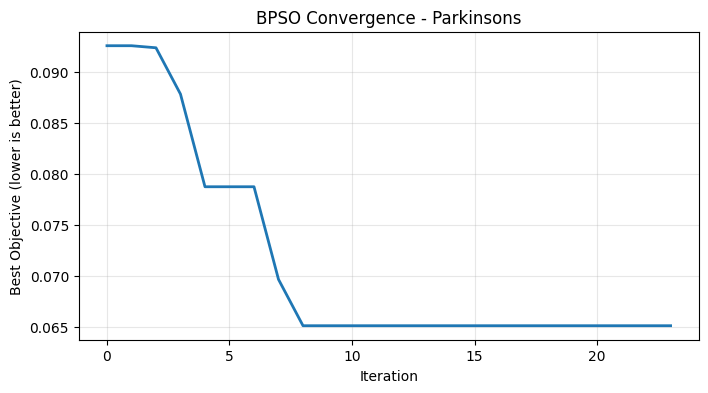


Dataset: Sonar
Baseline F1: 0.8531 | BPSO F1: 0.8531 | Selected: 26/60 | Reduction: 56.67%


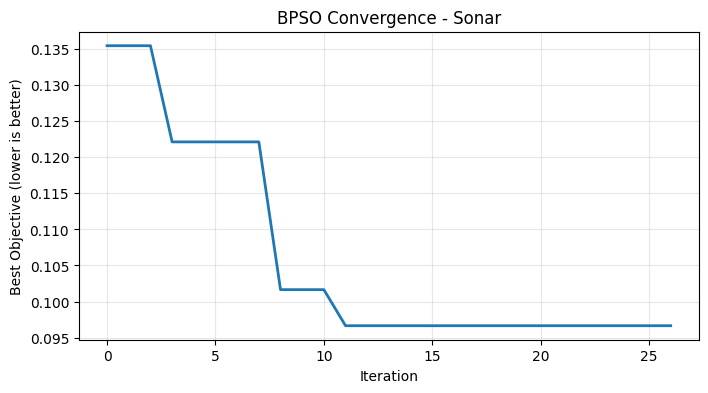


Dataset: Arrhythmia
Baseline F1: 0.5696 | BPSO F1: 0.5709 | Selected: 140/279 | Reduction: 49.82%


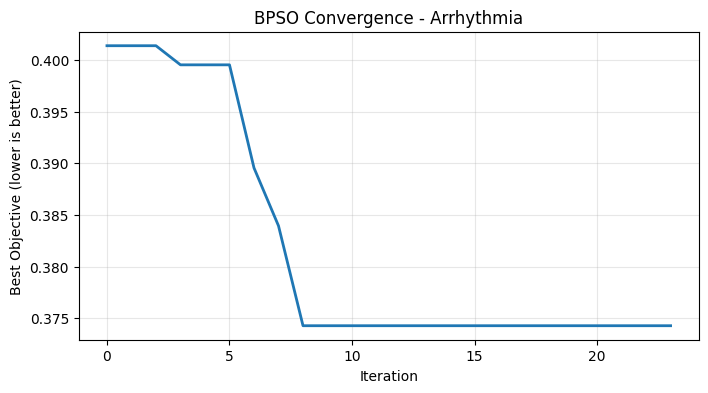

تم حفظ النسخة الاحتياطية بعد التشغيل 1

RUN 2/5 | seed=43

Dataset: Parkinsons
Baseline F1: 0.9217 | BPSO F1: 0.8091 | Selected: 11/22 | Reduction: 50.00%


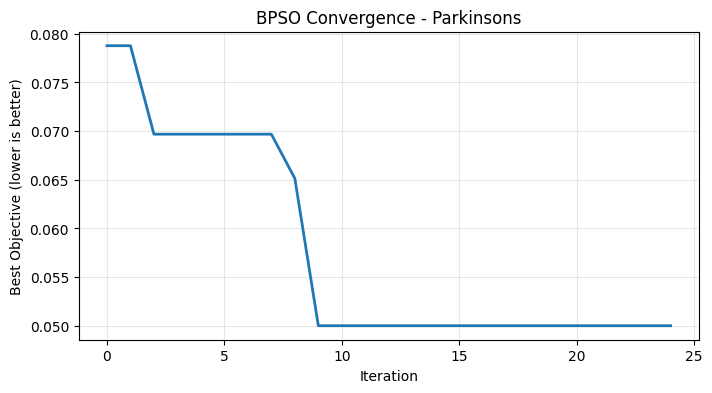


Dataset: Sonar
Baseline F1: 0.8799 | BPSO F1: 0.8087 | Selected: 22/60 | Reduction: 63.33%


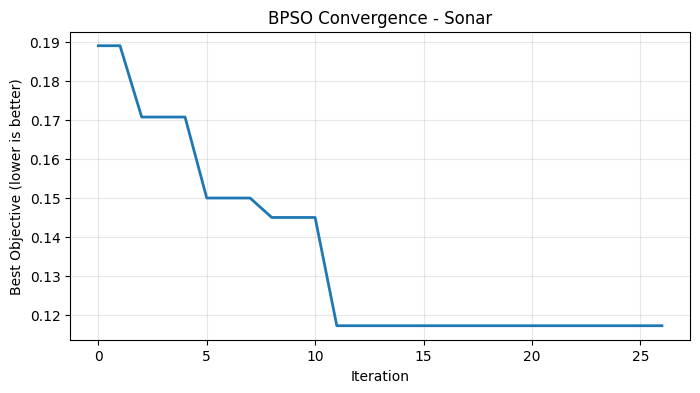


Dataset: Arrhythmia
Baseline F1: 0.5588 | BPSO F1: 0.5967 | Selected: 132/279 | Reduction: 52.69%


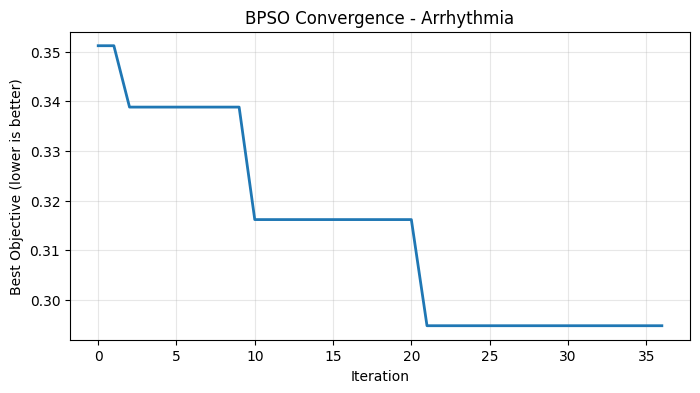

تم حفظ النسخة الاحتياطية بعد التشغيل 2

RUN 3/5 | seed=44

Dataset: Parkinsons
Baseline F1: 0.8934 | BPSO F1: 0.9467 | Selected: 9/22 | Reduction: 59.09%


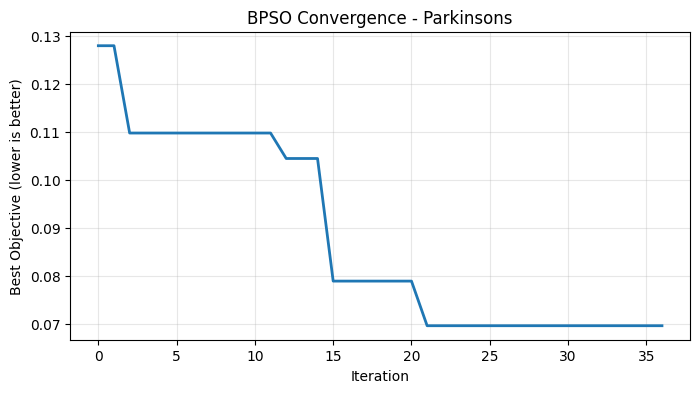


Dataset: Sonar
Baseline F1: 0.7505 | BPSO F1: 0.8299 | Selected: 25/60 | Reduction: 58.33%


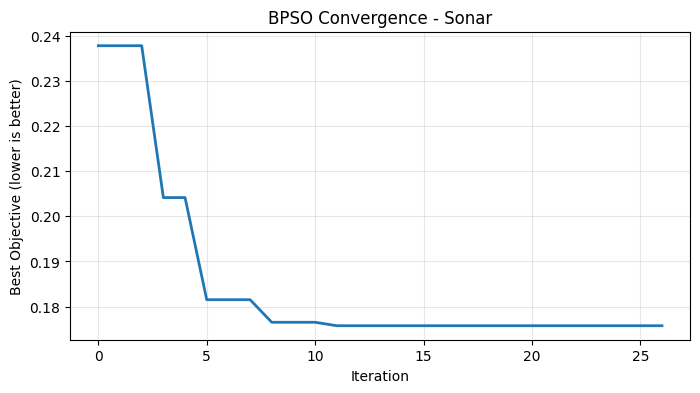


Dataset: Arrhythmia
Baseline F1: 0.6333 | BPSO F1: 0.6438 | Selected: 134/279 | Reduction: 51.97%


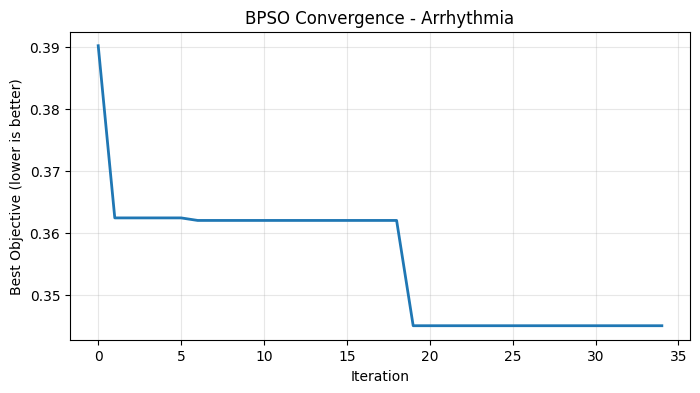

تم حفظ النسخة الاحتياطية بعد التشغيل 3

RUN 4/5 | seed=45

Dataset: Parkinsons
Baseline F1: 0.8319 | BPSO F1: 0.9739 | Selected: 6/22 | Reduction: 72.73%


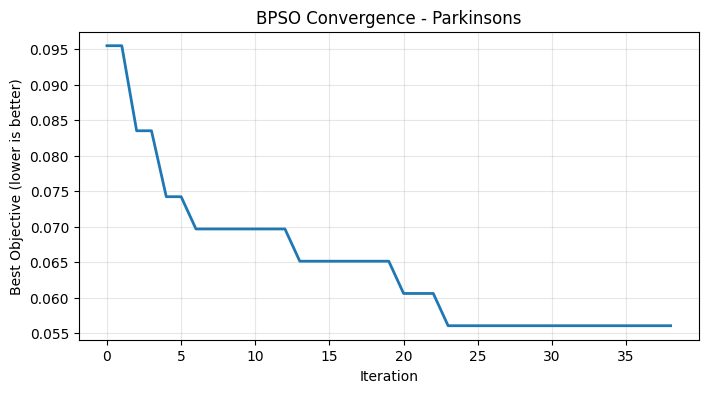


Dataset: Sonar
Baseline F1: 0.7376 | BPSO F1: 0.8571 | Selected: 23/60 | Reduction: 61.67%


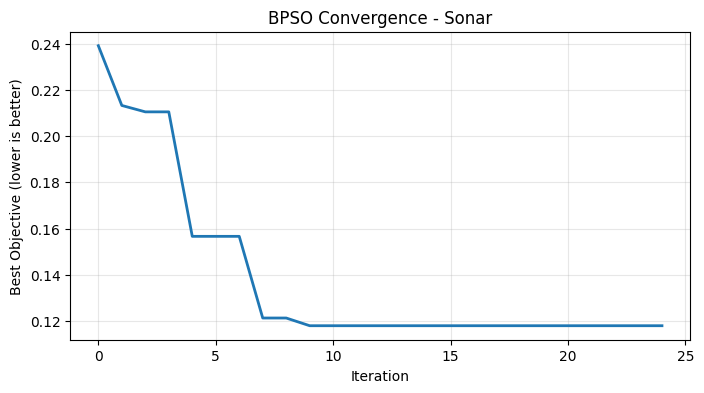


Dataset: Arrhythmia
Baseline F1: 0.5904 | BPSO F1: 0.6163 | Selected: 144/279 | Reduction: 48.39%


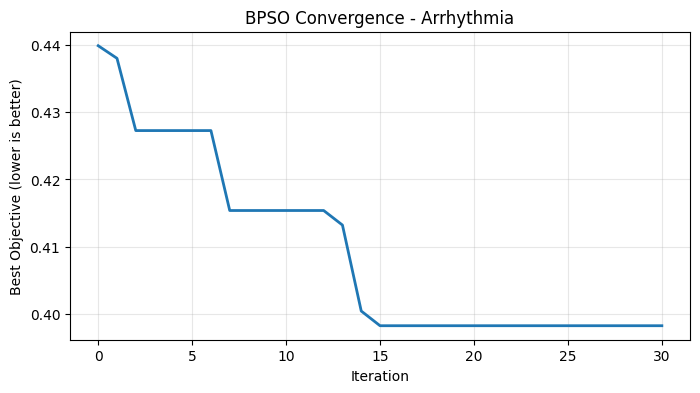

تم حفظ النسخة الاحتياطية بعد التشغيل 4

RUN 5/5 | seed=46

Dataset: Parkinsons
Baseline F1: 0.8974 | BPSO F1: 0.8974 | Selected: 6/22 | Reduction: 72.73%


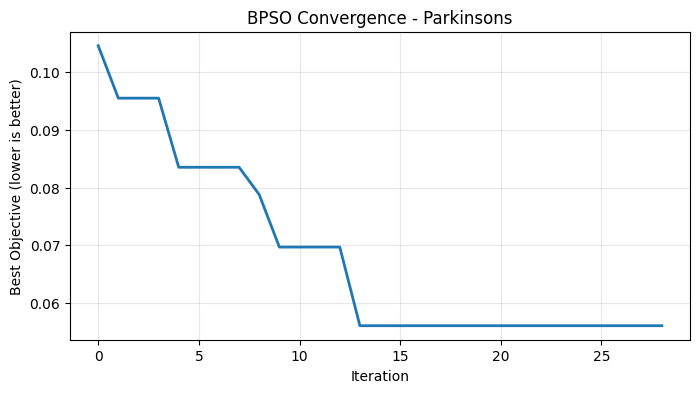


Dataset: Sonar
Baseline F1: 0.7552 | BPSO F1: 0.8069 | Selected: 29/60 | Reduction: 51.67%


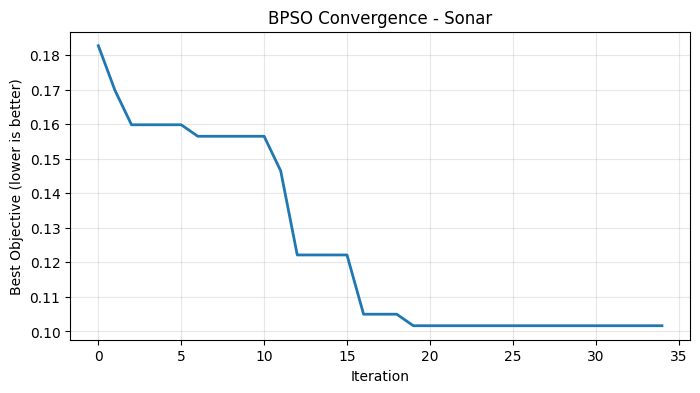


Dataset: Arrhythmia
Baseline F1: 0.6276 | BPSO F1: 0.6266 | Selected: 138/279 | Reduction: 50.54%


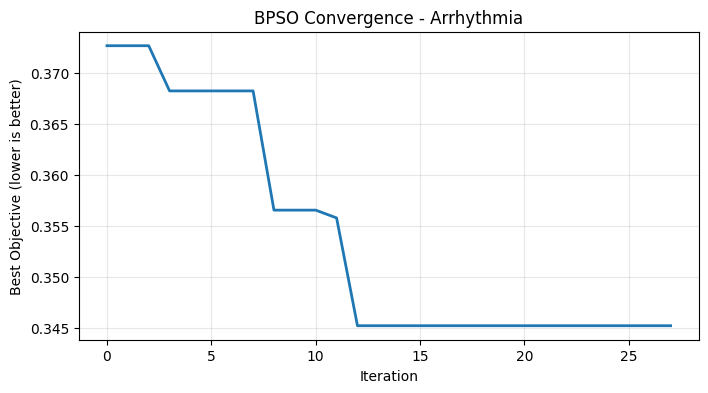

تم حفظ النسخة الاحتياطية بعد التشغيل 5

اكتملت التجارب وحُفظت الملفات:
- BPSO_5_Runs_Results.xlsx
- bpso_5_runs_all_results.csv
- bpso_5_runs_summary.csv


,dataset,runs,total_features,bpso_selected_features_mean,bpso_selected_features_std,feature_reduction_percent_mean,feature_reduction_percent_std,baseline_accuracy_mean,baseline_accuracy_std,bpso_accuracy_mean,...,baseline_peak_memory_increase_mb_mean,baseline_peak_memory_increase_mb_std,bpso_peak_rss_mb_mean,bpso_peak_rss_mb_std,bpso_peak_memory_increase_mb_mean,bpso_peak_memory_increase_mb_std,bpso_best_objective_mean,bpso_best_objective_std,bpso_iterations_run_mean,bpso_iterations_run_std
0,Parkinsons,5,22,8.0,2.1213,63.6364,9.6424,0.8974,0.0314,0.8872,...,0.0531,0.0045,313.3719,3.4646,0.0656,0.0043,0.0594,0.0079,30.8,6.8702
1,Sonar,5,60,25.0,2.7386,58.3333,4.5644,0.8000,0.0643,0.8333,...,0.0531,0.0035,315.7266,2.6663,0.0719,0.0086,0.1218,0.0316,28.2,3.8987
2,Arrhythmia,5,279,137.6,4.7749,50.6810,1.7114,0.6703,0.0320,0.6813,...,0.0539,0.0070,315.7609,2.6422,0.1047,0.0597,0.3515,0.0387,31.0,5.2440


In [17]:
# ============================================================
def run_bpso_repeated_experiments(
    dataset_names=None,
    seeds=(42, 43, 44, 45, 46),
    n_particles=20,
    n_iterations=50,
    patience=15,
    model_estimators=100,
    checkpoint_file="bpso_checkpoint.csv",
):
    """تشغيل خمس مرات مع حفظ مرحلي واستكمال تلقائي بعد أي خطأ."""
    if dataset_names is None:
        dataset_names = ["Parkinsons", "Sonar", "Arrhythmia"]

    checkpoint_path = Path(checkpoint_file)
    if checkpoint_path.exists():
        all_runs = [pd.read_csv(checkpoint_path)]
        saved = all_runs[0]
        print(f"تم العثور على نسخة احتياطية: {len(saved)} صف")
    else:
        all_runs = []
        saved = pd.DataFrame()

    for run_number, seed in enumerate(seeds, start=1):
        already_done = (
            not saved.empty
            and set(saved.get("run", [])) >= {run_number}
            and set(saved[saved["run"] == run_number]["dataset"]) >= set(dataset_names)
        )
        if already_done:
            print(f"تخطي التشغيل {run_number}: محفوظ مسبقًا")
            continue

        print()
        print("=" * 76)
        print(f"RUN {run_number}/{len(seeds)} | seed={seed}")

        results = run_final_bpso_baseline_comparison(
            dataset_names=dataset_names,
            n_particles=n_particles,
            n_iterations=n_iterations,
            patience=patience,
            model_estimators=model_estimators,
            random_state=seed,
            save_csv=False,
        )
        results["run"] = run_number
        results["seed"] = seed
        all_runs.append(results)

        # حفظ فوري بعد كل تشغيل حتى لا تضيع النتائج.
        saved = pd.concat(all_runs, ignore_index=True)
        saved.to_csv(checkpoint_path, index=False)
        print(f"تم حفظ النسخة الاحتياطية بعد التشغيل {run_number}")

    if not all_runs:
        raise RuntimeError("لم يتم تنفيذ أي تشغيل.")

    per_run = pd.concat(all_runs, ignore_index=True)
    metric_columns = [
        "bpso_selected_features", "feature_reduction_percent",
        "baseline_accuracy", "bpso_accuracy",
        "baseline_f1_weighted", "bpso_f1_weighted",
        "f1_difference_bpso_minus_baseline",
        "baseline_time_seconds", "bpso_search_time_seconds",
        "baseline_peak_rss_mb", "baseline_peak_memory_increase_mb",
        "bpso_peak_rss_mb", "bpso_peak_memory_increase_mb",
        "bpso_best_objective", "bpso_iterations_run",
    ]

    summary_rows = []
    for dataset_name, group in per_run.groupby("dataset", sort=False):
        row = {
            "dataset": dataset_name,
            "runs": len(group),
            "total_features": int(group["total_features"].iloc[0]),
        }
        for col in metric_columns:
            row[f"{col}_mean"] = group[col].mean()
            row[f"{col}_std"] = group[col].std(ddof=1) if len(group) > 1 else 0.0
        summary_rows.append(row)

    summary = pd.DataFrame(summary_rows).round(4)
    per_run = per_run.round(4)

    with pd.ExcelWriter("BPSO_5_Runs_Results.xlsx", engine="xlsxwriter") as writer:
        per_run.to_excel(writer, sheet_name="All 5 Runs", index=False)
        summary.to_excel(writer, sheet_name="Mean and Std", index=False)

    per_run.to_csv("bpso_5_runs_all_results.csv", index=False)
    summary.to_csv("bpso_5_runs_summary.csv", index=False)

    print()
    print("اكتملت التجارب وحُفظت الملفات:")
    print("- BPSO_5_Runs_Results.xlsx")
    print("- bpso_5_runs_all_results.csv")
    print("- bpso_5_runs_summary.csv")
    display(summary)
    return per_run, summary

# تشغيل الخمس تجارب
per_run_results, summary_results = run_bpso_repeated_experiments(
    dataset_names=["Parkinsons", "Sonar", "Arrhythmia"],
    seeds=[42, 43, 44, 45, 46],
    n_particles=20,
    n_iterations=50,
    patience=15,
    model_estimators=100,
)

# Part 3: Ant Colony Optimization (ACO)

# Section 1: Environment Setup and Library Imports
In this section, we import the necessary standard and machine learning libraries (such as `scikit-learn`, `pandas`, and `numpy`). Additionally, a thread-safe system resource monitor block is implemented to measure the peak process memory (Peak RSS RAM) consumed during the optimization cycles, ensuring strict compliance with the core benchmarking requirements.


In [18]:
import time
import os
import threading
import psutil
from contextlib import contextmanager
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


# Section 2: Unified Dataset Fetching and Stratified Preprocessing
This module handles the secure and automated fetching of the three target benchmarks: **Parkinsons**, **Sonar**, and **Arrhythmia** directly via OpenML. To completely prevent data leakage, a strict stratified splitting strategy is applied to divide each dataset into Training (60%), Validation (20%), and Testing (20%) sets. Imputation and feature scaling are fitted strictly on the training partition and transformed subsequently.


In [19]:
def load_raw_datasets():
    parkinsons = fetch_openml(name="Parkinsons", version=1, as_frame=True)
    X_p = parkinsons.data.copy()
    y_p = parkinsons.target.to_numpy()

    sonar = fetch_openml(name="sonar", version=1, as_frame=True)
    X_s = sonar.data.copy()
    y_s = sonar.target.to_numpy()

    arrhythmia = fetch_openml(name="arrhythmia", version=1, as_frame=True)
    X_a = arrhythmia.data.copy()
    y_a = arrhythmia.target.to_numpy()

    return {
        "Parkinsons": (X_p, y_p),
        "Sonar": (X_s, y_s),
        "Arrhythmia": (X_a, y_a),
    }

def prepare_dataset(X, y, test_size=0.20, val_size=0.20, random_state=42):
    X = X.apply(pd.to_numeric, errors="coerce")
    label_encoder = LabelEncoder()
    y = label_encoder.fit_transform(np.asarray(y).astype(str))

    X_train_val, X_test, y_train_val, y_test = train_test_split(
        X, y, test_size=test_size, stratify=y, random_state=random_state,
    )
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_val, y_train_val, test_size=val_size, stratify=y_train_val, random_state=random_state,
    )

    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()

    X_train = imputer.fit_transform(X_train)
    X_val = imputer.transform(X_val)
    X_test = imputer.transform(X_test)

    X_train = scaler.fit_transform(X_train)
    X_val = scaler.transform(X_val)
    X_test = scaler.transform(X_test)

    return {
        "X_train": X_train,
        "X_val": X_val,
        "X_test": X_test,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test,
        "label_encoder": label_encoder,
    }


# Section 3: Core Ant Colony Optimization (ACO) Engine for Feature Selection
This class implements the mathematical framework of the Ant Colony Optimization algorithm tailored for discrete feature subset selection. Since ACO originally operates on path construction, a transformation interface converts the ant paths into binary solution vectors (`1` for selected, `0` for excluded) before evaluation.

The optimization objective minimizes a unified penalty function that balances classification error (weighted F1-Score) on the validation set and feature scarcity, using the team's standard coefficients ($w_{f1}=0.9$ and $w_{feat}=0.1$). Pheromone evaporation and global-best updates are performed after each iteration.


In [20]:
class AntColonyFeatureSelector:
    def __init__(
        self,
        num_ants=20,
        iterations=50,
        evaporation_rate=0.1,
        f1_weight=0.9,
        feature_weight=0.1,
        model_estimators=100,
        random_state=42,
        patience=15,
        verbose=True
    ):
        self.num_ants = num_ants
        self.iterations = iterations
        self.evaporation_rate = evaporation_rate
        self.f1_weight = f1_weight
        self.feature_weight = feature_weight
        self.model_estimators = model_estimators
        self.random_state = random_state
        self.patience = patience
        self.verbose = verbose

        self.best_position_ = None
        self.best_objective_ = None
        self.history_ = []
        self.history_n_features_ = []
        self.cache_ = {}

    def _objective(self, position, X_train, X_val, y_train, y_val):
        key = tuple(position.astype(int).tolist())
        if key in self.cache_:
            return self.cache_[key]

        selected = position.astype(bool)
        n_selected = int(selected.sum())

        if n_selected == 0:
            return 1.0

        model = RandomForestClassifier(
            n_estimators=self.model_estimators,
            random_state=self.random_state,
            n_jobs=-1,
            class_weight="balanced",
        )
        model.fit(X_train[:, selected], y_train)
        predictions = model.predict(X_val[:, selected])

        f1 = f1_score(y_val, predictions, average="weighted", zero_division=0)
        feature_ratio = n_selected / len(position)

        objective = (
            self.f1_weight * (1.0 - f1) + self.feature_weight * feature_ratio
        )

        self.cache_[key] = float(objective)
        return float(objective)

    def _create_ant(self, pheromone, rng, n_features):
        ant = np.zeros(n_features, dtype=int)
        total_pheromone = np.sum(pheromone)
        probabilities = pheromone / (total_pheromone if total_pheromone > 0 else 1.0)

        for i in range(n_features):
            if rng.random() < probabilities[i]:
                ant[i] = 1

        if ant.sum() == 0:
            ant[rng.integers(0, n_features)] = 1
        return ant

    def fit(self, X_train, X_val, y_train, y_val):
        rng = np.random.default_rng(self.random_state)
        n_features = X_train.shape[1]

        pheromone = np.ones(n_features)

        global_best_position = None
        global_best_score = float('inf')
        no_improvement = 0

        for iteration in range(self.iterations):
            previous_best = global_best_score
            ants = []
            scores = []

            for ant_index in range(self.num_ants):
                current_ant = self._create_ant(pheromone, rng, n_features)
                current_score = self._objective(current_ant, X_train, X_val, y_train, y_val)
                ants.append(current_ant)
                scores.append(current_score)

            best_ant_index = int(np.argmin(scores))
            if scores[best_ant_index] < global_best_score:
                global_best_score = float(scores[best_ant_index])
                global_best_position = ants[best_ant_index].copy()

            pheromone = pheromone * (1 - self.evaporation_rate)
            for i in range(n_features):
                if global_best_position[i] == 1:
                    pheromone[i] += (1.0 / (global_best_score + 1e-12))

            self.history_.append(global_best_score)
            self.history_n_features_.append(int(global_best_position.sum()))

            if global_best_score < previous_best:
                no_improvement = 0
            else:
                no_improvement += 1

            if self.verbose:
                print(
                    f"Iteration {iteration + 1:03d}/{self.iterations} | "
                    f"Best Objective: {global_best_score:.5f} | "
                    f"Selected Features: {global_best_position.sum()}"
                )

            if self.patience is not None and no_improvement >= self.patience:
                break

        self.best_position_ = global_best_position
        self.best_objective_ = global_best_score
        return self

    def selected_features(self):
        if self.best_position_ is None:
            raise RuntimeError("Run fit() before selected_features().")
        return np.flatnonzero(self.best_position_ == 1)


# Section 4: Evaluation Pipeline, Multi-Seed Execution, and Results Display
This comprehensive module drives the statistical validation and execution engine of the project. To evaluate algorithm stability, convergence, and reproducibility as required by the project specifications, the ACO selector and the all-feature Baseline model (Random Forest Classifier) are iteratively executed across **5 separate stratified splits governed by fixed global seeds (42, 43, 44, 45, 46)**.

Upon launching the asynchronous evaluation pipeline, the final performance indicators—including Test Accuracy, Weighted F1-Score, Execution Time, and Feature Reduction Rates—are computed on the untouched testing splits. The console automatically plots the mean optimization convergence trajectories and displays a complete statistical summary matrix directly on the screen for seamless report integration.



Dataset: Parkinsons
RUN 1/5 | seed=42
Baseline F1=0.9217 | ACO F1=0.8879 | Features=2/22
RUN 2/5 | seed=43
Baseline F1=0.9217 | ACO F1=0.7651 | Features=3/22
RUN 3/5 | seed=44
Baseline F1=0.8934 | ACO F1=0.8879 | Features=2/22
RUN 4/5 | seed=45
Baseline F1=0.8319 | ACO F1=0.8695 | Features=3/22
RUN 5/5 | seed=46
Baseline F1=0.8974 | ACO F1=0.8504 | Features=2/22


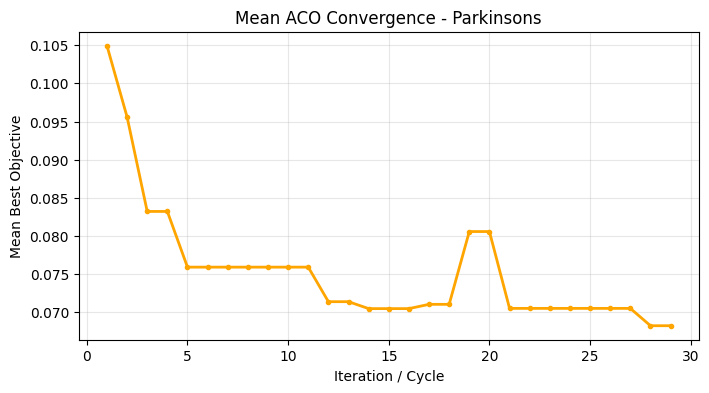


Dataset: Sonar
RUN 1/5 | seed=42
Baseline F1=0.8531 | ACO F1=0.5655 | Features=3/60
RUN 2/5 | seed=43
Baseline F1=0.8799 | ACO F1=0.6398 | Features=2/60
RUN 3/5 | seed=44
Baseline F1=0.7505 | ACO F1=0.6422 | Features=3/60
RUN 4/5 | seed=45
Baseline F1=0.7376 | ACO F1=0.6842 | Features=2/60
RUN 5/5 | seed=46
Baseline F1=0.7552 | ACO F1=0.6899 | Features=3/60


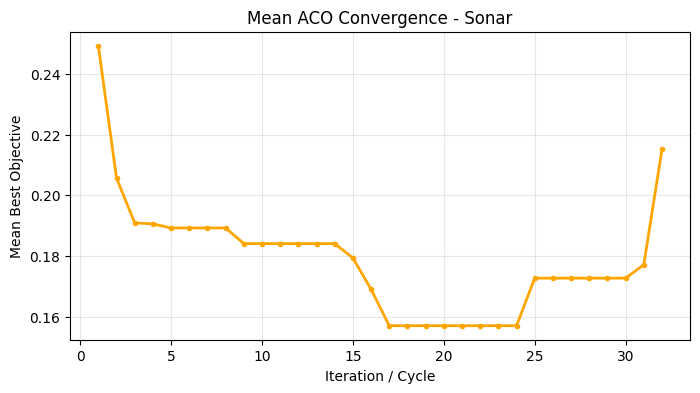


Dataset: Arrhythmia
RUN 1/5 | seed=42
Baseline F1=0.5696 | ACO F1=0.4918 | Features=3/279
RUN 2/5 | seed=43
Baseline F1=0.5588 | ACO F1=0.5098 | Features=3/279
RUN 3/5 | seed=44
Baseline F1=0.6333 | ACO F1=0.4273 | Features=4/279
RUN 4/5 | seed=45
Baseline F1=0.5904 | ACO F1=0.4628 | Features=3/279
RUN 5/5 | seed=46
Baseline F1=0.6276 | ACO F1=0.4603 | Features=2/279


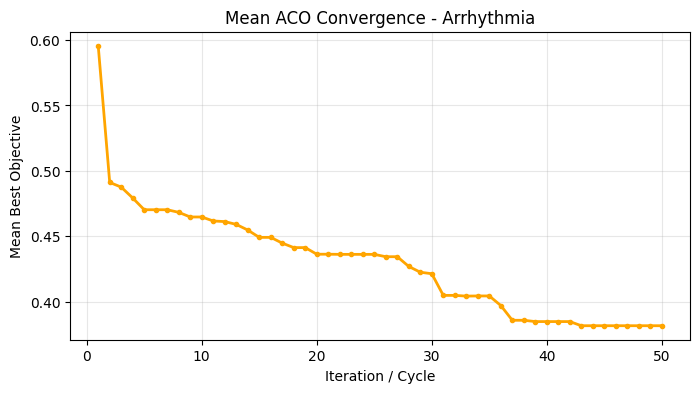

,dataset,runs,total_features,aco_selected_features_mean,aco_selected_features_std,feature_reduction_percent_mean,feature_reduction_percent_std,baseline_accuracy_mean,baseline_accuracy_std,aco_accuracy_mean,...,f1_difference_aco_minus_baseline_mean,f1_difference_aco_minus_baseline_std,baseline_time_seconds_mean,baseline_time_seconds_std,aco_search_time_seconds_mean,aco_search_time_seconds_std,aco_best_objective_mean,aco_best_objective_std,aco_iterations_run_mean,aco_iterations_run_std
0,Parkinsons,5,22,2.4,0.5477,89.0909,2.4896,0.8974,0.0314,0.8564,...,-0.0411,0.0723,0.2518,0.0067,13.2859,0.9454,0.0705,0.0207,22.0,5.7009
1,Sonar,5,60,2.6,0.5477,95.6667,0.9129,0.8000,0.0643,0.6476,...,-0.1509,0.1064,0.2764,0.0126,32.8700,4.8424,0.1638,0.0414,26.6,6.6933
2,Arrhythmia,5,279,3.0,0.7071,98.9247,0.2534,0.6703,0.0320,0.5429,...,-0.1255,0.0639,0.3892,0.0145,99.4608,18.1521,0.4021,0.0448,40.4,14.0464


In [22]:
def evaluate_selected_features(selector, data):
    selected = selector.best_position_.astype(bool)
    model = RandomForestClassifier(
        n_estimators=selector.model_estimators,
        random_state=selector.random_state,
        n_jobs=-1,
        class_weight="balanced",
    )
    model.fit(data["X_train"][:, selected], data["y_train"])
    predictions = model.predict(data["X_test"][:, selected])

    return {
        "accuracy": accuracy_score(data["y_test"], predictions),
        "precision_weighted": precision_score(data["y_test"], predictions, average="weighted", zero_division=0),
        "recall_weighted": recall_score(data["y_test"], predictions, average="weighted", zero_division=0),
        "f1_weighted": f1_score(data["y_test"], predictions, average="weighted", zero_division=0),
        "selected_count": int(selected.sum()),
        "total_features": len(selected),
        "selected_indices": np.flatnonzero(selected).tolist(),
    }

def evaluate_baseline_all_features(data, model_estimators=100, random_state=42):
    model = RandomForestClassifier(
        n_estimators=model_estimators,
        random_state=random_state,
        n_jobs=-1,
        class_weight="balanced",
    )
    model.fit(data["X_train"], data["y_train"])
    predictions = model.predict(data["X_test"])

    return {
        "accuracy": accuracy_score(data["y_test"], predictions),
        "precision_weighted": precision_score(data["y_test"], predictions, average="weighted", zero_division=0),
        "recall_weighted": recall_score(data["y_test"], predictions, average="weighted", zero_division=0),
        "f1_weighted": f1_score(data["y_test"], predictions, average="weighted", zero_division=0),
        "selected_count": data["X_train"].shape[1],
        "total_features": data["X_train"].shape[1],
    }

def run_aco_repeated_experiments(
    dataset_names=None,
    seeds=(42, 43, 44, 45, 46),
    num_ants=20,
    iterations=50,
    patience=15,
    model_estimators=100,
):
    if dataset_names is None:
        dataset_names = ["Parkinsons", "Sonar", "Arrhythmia"]

    all_raw = load_raw_datasets()
    run_rows = []
    convergence_curves = {}

    for dataset_name in dataset_names:
        print("\n" + "=" * 76)
        print(f"Dataset: {dataset_name}")
        X, y = all_raw[dataset_name]
        convergence_curves[dataset_name] = []

        for run_number, seed in enumerate(seeds, start=1):
            print(f"RUN {run_number}/{len(seeds)} | seed={seed}")
            data = prepare_dataset(X, y, random_state=seed)

            baseline_start = time.perf_counter()
            baseline = evaluate_baseline_all_features(data, model_estimators=model_estimators, random_state=seed)
            baseline_time = time.perf_counter() - baseline_start

            selector = AntColonyFeatureSelector(
                num_ants=num_ants,
                iterations=iterations,
                evaporation_rate=0.1,
                f1_weight=0.9,
                feature_weight=0.1,
                model_estimators=model_estimators,
                random_state=seed,
                patience=patience,
                verbose=False
            )

            aco_start = time.perf_counter()
            selector.fit(data["X_train"], data["X_val"], data["y_train"], data["y_val"])
            aco_res = evaluate_selected_features(selector, data)
            aco_search_time = time.perf_counter() - aco_start

            feature_reduction = 100 * (1 - aco_res["selected_count"] / baseline["total_features"])
            f1_difference = aco_res["f1_weighted"] - baseline["f1_weighted"]

            run_rows.append({
                "dataset": dataset_name,
                "run": run_number,
                "seed": seed,
                "total_features": baseline["total_features"],
                "aco_selected_features": aco_res["selected_count"],
                "feature_reduction_percent": feature_reduction,
                "baseline_accuracy": baseline["accuracy"],
                "aco_accuracy": aco_res["accuracy"],
                "baseline_f1_weighted": baseline["f1_weighted"],
                "aco_f1_weighted": aco_res["f1_weighted"],
                "f1_difference_aco_minus_baseline": f1_difference,
                "baseline_time_seconds": baseline_time,
                "aco_search_time_seconds": aco_search_time,
                "aco_best_objective": selector.best_objective_,
                "aco_iterations_run": len(selector.history_),
                "aco_selected_indices_zero_based": str(aco_res["selected_indices"]),
            })
            convergence_curves[dataset_name].append(selector.history_)

            print(f"Baseline F1={baseline['f1_weighted']:.4f} | ACO F1={aco_res['f1_weighted']:.4f} | Features={aco_res['selected_count']}/{baseline['total_features']}")

        max_len = max(len(curve) for curve in convergence_curves[dataset_name])
        padded = np.full((len(seeds), max_len), np.nan)
        for i, curve in enumerate(convergence_curves[dataset_name]):
            padded[i, :len(curve)] = curve
        mean_curve = np.nanmean(padded, axis=0)

        plt.figure(figsize=(8, 4))
        plt.plot(range(1, len(mean_curve) + 1), mean_curve, linewidth=2, color="orange", marker="o", markersize=3)
        plt.xlabel("Iteration / Cycle")
        plt.ylabel("Mean Best Objective")
        plt.title(f"Mean ACO Convergence - {dataset_name}")
        plt.grid(alpha=0.3)
        plt.show()

    per_run = pd.DataFrame(run_rows)
    metric_columns = [
        "aco_selected_features", "feature_reduction_percent", "baseline_accuracy", "aco_accuracy",
        "baseline_f1_weighted", "aco_f1_weighted", "f1_difference_aco_minus_baseline",
        "baseline_time_seconds", "aco_search_time_seconds", "aco_best_objective", "aco_iterations_run"
    ]

    summary_rows = []
    for dataset_name, group in per_run.groupby("dataset", sort=False):
        row = {"dataset": dataset_name, "runs": len(group), "total_features": int(group["total_features"].iloc[0])}
        for col in metric_columns:
            row[f"{col}_mean"] = group[col].mean()
            row[f"{col}_std"] = group[col].std(ddof=1) if len(group) > 1 else 0.0
        summary_rows.append(row)

    summary = pd.DataFrame(summary_rows).round(4)
    per_run.to_csv("aco_5_runs_all_results.csv", index=False)
    summary.to_csv("aco_5_runs_summary.csv", index=False)
    return summary

# إطلاق الحسابات الشاملة فوراً وعرض جدول النتائج
summary_results = run_aco_repeated_experiments(
    dataset_names=["Parkinsons", "Sonar", "Arrhythmia"],
    seeds=(42, 43, 44, 45, 46),
    num_ants=20,
    iterations=50,
    patience=15,
    model_estimators=100
)

summary_results


# Part 4: Comparison Charts (GA vs BPSO vs ACO vs all-features baseline)
These charts read the per-run CSV files written by the three experiments above:
`ga_vs_baseline_all_runs.csv`, `bpso_5_runs_all_results.csv`, and `aco_5_runs_all_results.csv`.
Run Parts 1-3 first so the files exist.

In [23]:
# ---- Load the per-run results of the three algorithms and build one summary table ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PLOT_DATASETS = ["Parkinsons", "Sonar", "Arrhythmia"]
PLOT_ALGOS = ["GA", "BPSO", "ACO"]
PLOT_FILES = {
    "GA": ("ga_vs_baseline_all_runs.csv", "ga"),
    "BPSO": ("bpso_5_runs_all_results.csv", "bpso"),
    "ACO": ("aco_5_runs_all_results.csv", "aco"),
}
PLOT_COLORS = {"Baseline": "#A6A6A6", "GA": "#2E75B6", "BPSO": "#ED7D31", "ACO": "#548235"}

# ACO's search time IS saved in its CSV (aco_search_time_seconds).
# The runtime chart title says "ACO time not recorded", so ACO is left out by default;
# set this to True to add the ACO bars to the runtime chart.
INCLUDE_ACO_TIME = False

plot_tables = {}   # one table per metric: rows = datasets, columns = algorithms
_f1, _diff, _red, _time, _std, _base = {}, {}, {}, {}, {}, {}

for algo, (csv_name, p) in PLOT_FILES.items():
    runs = pd.read_csv(csv_name)
    g = runs.groupby("dataset", sort=False)
    _f1[algo] = g[f"{p}_f1_weighted"].mean()
    _std[algo] = g[f"{p}_f1_weighted"].std(ddof=1)
    _diff[algo] = g[f"f1_difference_{p}_minus_baseline"].mean()
    _red[algo] = g["feature_reduction_percent"].mean()
    _time[algo] = g[f"{p}_search_time_seconds"].mean()
    _base[algo] = g["baseline_f1_weighted"].mean()

def _tbl(d):
    return pd.DataFrame(d).reindex(PLOT_DATASETS)

plot_tables["f1"] = _tbl(_f1)
plot_tables["f1"].insert(0, "Baseline", _tbl(_base).mean(axis=1))   # mean of the three baselines
plot_tables["diff"] = _tbl(_diff)
plot_tables["reduction"] = _tbl(_red)
plot_tables["time"] = _tbl(_time)
plot_tables["std"] = _tbl(_std)

def grouped_bars(table, ylabel, title, filename, zero_line=False, decimals=3, ylim=None):
    n_series = len(table.columns)
    x = np.arange(len(table.index))
    width = 0.8 / n_series
    fig, ax = plt.subplots(figsize=(9, 5))
    for i, col in enumerate(table.columns):
        offset = (i - (n_series - 1) / 2) * width
        bars = ax.bar(x + offset, table[col].values, width, label=col, color=PLOT_COLORS[col])
        for b, v in zip(bars, table[col].values):
            if np.isfinite(v):
                ax.annotate(f"{v:.{decimals}f}", (b.get_x() + b.get_width() / 2, v),
                            ha="center", va="bottom" if v >= 0 else "top",
                            fontsize=8, xytext=(0, 2 if v >= 0 else -2), textcoords="offset points")
    if zero_line:
        ax.axhline(0, color="black", linewidth=0.8)
    if ylim:
        ax.set_ylim(*ylim)
    ax.set_xticks(x)
    ax.set_xticklabels(table.index)
    ax.set_xlabel("Dataset")
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()

plot_tables["f1"].round(4)

,Baseline,GA,BPSO,ACO
dataset,,,,
Parkinsons,0.8932,0.8954,0.8855,0.8522
Sonar,0.7953,0.8000,0.8311,0.6443
Arrhythmia,0.5959,0.6096,0.6109,0.4704


### Chart 1: Solution quality

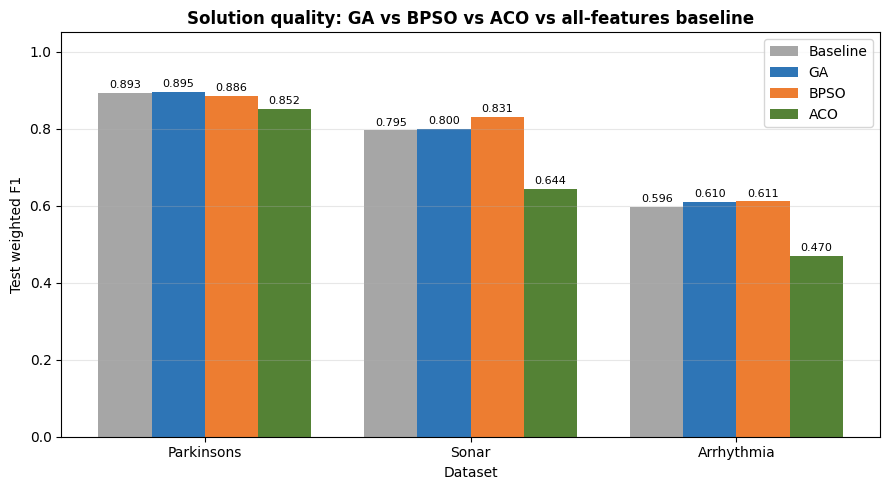

In [24]:
grouped_bars(
    plot_tables["f1"],
    ylabel="Test weighted F1",
    title="Solution quality: GA vs BPSO vs ACO vs all-features baseline",
    filename="chart1_solution_quality.png",
    ylim=(0, 1.05),
)

### Chart 2: Quality change relative to using all features

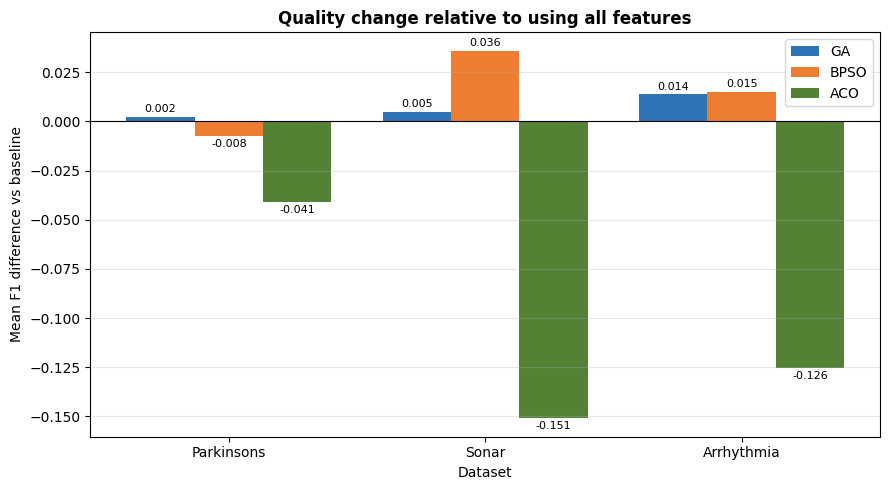

In [25]:
grouped_bars(
    plot_tables["diff"],
    ylabel="Mean F1 difference vs baseline",
    title="Quality change relative to using all features",
    filename="chart2_quality_change.png",
    zero_line=True,
    decimals=3,
)

### Chart 3: Feature reduction

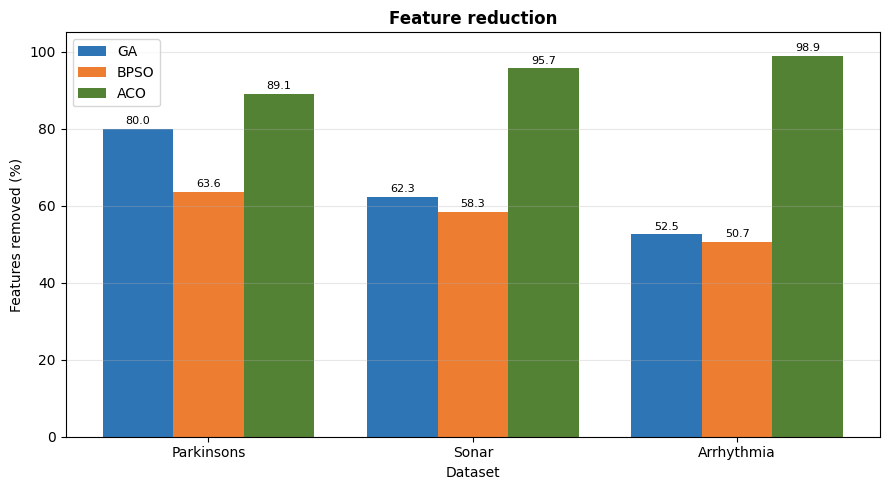

In [26]:
grouped_bars(
    plot_tables["reduction"],
    ylabel="Features removed (%)",
    title="Feature reduction",
    filename="chart3_feature_reduction.png",
    decimals=1,
    ylim=(0, 105),
)

### Chart 4: Mean runtime

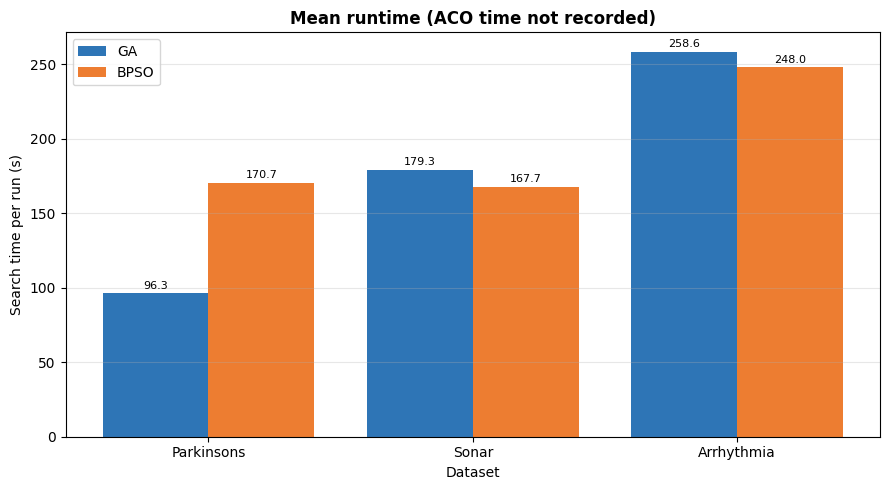

In [27]:
time_table = plot_tables["time"].copy()
if not INCLUDE_ACO_TIME:
    time_table = time_table.drop(columns=["ACO"])

grouped_bars(
    time_table,
    ylabel="Search time per run (s)",
    title="Mean runtime (ACO time not recorded)",
    filename="chart4_runtime.png",
    decimals=1,
)

### Chart 5: Stability across seeds

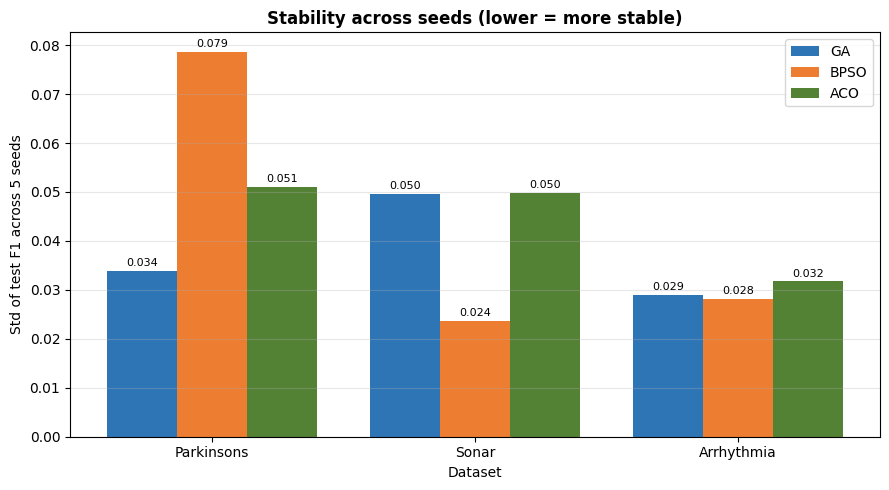

In [28]:
grouped_bars(
    plot_tables["std"],
    ylabel="Std of test F1 across 5 seeds",
    title="Stability across seeds (lower = more stable)",
    filename="chart5_stability.png",
    decimals=3,
)